In [ ]:
import sys, subprocess

PACKAGES = [
    "chonkie[st]==1.0.10",
    "beautifulsoup4>=4.12",
    "mwparserfromhell>=0.7",
    "datasketch>=1.6",
    "emoji>=2.12",
    "tiktoken>=0.8",
    "scikit-learn>=1.4",
    "pandas>=2.1",
    "matplotlib>=3.8",
    "seaborn>=0.13",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PACKAGES])

0

In [ ]:
import collections
import hashlib
import json
import math
import os
import random
import re
import statistics
import time
import unicodedata
from collections import Counter, defaultdict
from pathlib import Path
from urllib.parse import quote

import emoji
import matplotlib.pyplot as plt
import mwparserfromhell
import numpy as np
import pandas as pd
import seaborn as sns
import tiktoken
from bs4 import BeautifulSoup
from datasketch import MinHash, MinHashLSH
from sklearn.feature_extraction.text import TfidfVectorizer

import chonkie
from chonkie import TokenChunker, SentenceChunker, SemanticChunker, SDPMChunker

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

OUT = Path("/content/kt2_outputs") if Path("/content").exists() else Path("kt2_outputs")
OUT.mkdir(parents=True, exist_ok=True)

KS = (1, 3, 5, 10)
PRIMARY_K = 5
CHUNK_SIZE = 512
CHUNK_OVERLAP = 0
MINHASH_THRESHOLD = 0.88
MINHASH_PERMUTATIONS = 128
EVIDENCE_COVERAGE_THRESHOLD = 0.50
SEMANTIC_MODEL = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"

print("Chonkie:", chonkie.__version__)
print("Папка результатов:", OUT)

Chonkie: 1.0.10
Папка результатов: /content/kt2_outputs


Загрузка корпуса и gold

In [ ]:
%pip -q install tiktoken datasketch scikit-learn matplotlib numpy

import hashlib
import urllib.request
import urllib.error
import shutil
from pathlib import Path

URL = 'https://dumps.wikimedia.org/ruwikivoyage/20260901/ruwikivoyage-20260901-pages-articles-multistream.xml.bz2'
DATA = Path('/content/ruwikivoyage-20260901.xml.bz2')

if not DATA.exists():
  request = urllib.request.Request(URL, headers={'User-Agent': 'RAG-course-EDA/1.0 (academic project)'})
  with urllib.request.urlopen(request, timeout=30) as response, DATA.open('wb') as out:
      shutil.copyfileobj(response, out)
  print('Архив скачан автоматически.')

Архив скачан автоматически.


In [ ]:
import bz2
import collections
import hashlib
import html
import json
import re
import sys
from functools import lru_cache
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tiktoken
from datasketch import MinHash, MinHashLSH
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

DATA = Path('/content/ruwikivoyage-20260901.xml.bz2')
OUT = Path('/content/eda_output')
OUT.mkdir(exist_ok=True)
ENC = tiktoken.get_encoding('cl100k_base')
NS = '{http://www.mediawiki.org/xml/export-0.11/}'
pages = []
with bz2.open(DATA, 'rb') as stream:
    for event, node in ET.iterparse(stream, events=('end',)):
        if node.tag != NS + 'page':
            continue
        ns = node.findtext(NS + 'ns')
        if ns == '0':
            text = node.findtext('./' + NS + 'revision/' + NS + 'text') or ''
            title = node.findtext(NS + 'title') or ''
            pages.append(dict(title=title, text=text, redirect=node.find(NS+'redirect') is not None))
        node.clear()

# Берем первые 500 страниц хэшируем чтобы получать одну и ту же выборку независимо от порядка страниц в XML
population_size = len(pages)
pages = sorted(pages, key=lambda p: hashlib.sha256(p['title'].encode()).digest())[:500]

for p in pages:
    p['tokens'] = len(ENC.encode(p['text'], disallowed_special=()))
counts = np.array([p['tokens'] for p in pages])
print('Parsed pages:', len(pages), 'total tokens:', int(counts.sum()), flush=True)

Parsed pages: 500 total tokens: 4562491


In [ ]:
import json

with open("/content/gold_all.json", encoding="utf-8") as f:
    CANDIDATES = json.load(f)

print(f"Восстановлено кандидатов: {len(CANDIDATES)}")

Восстановлено кандидатов: 24


In [ ]:
def sha256_text(value: str) -> str:
    return hashlib.sha256(value.encode("utf-8")).hexdigest()

docs = []
for p in pages:
    if not isinstance(p, dict) or not isinstance(p.get("title"), str) or not isinstance(p.get("text"), str):
        raise ValueError("Каждая страница корпуса должна содержать строковые title и text.")
    title = p["title"].strip()
    doc_id = str(p.get("doc_id") or sha256_text(title)[:20])
    docs.append({
        "doc_id": doc_id,
        "title": title,
        "text": p["text"],
        "url": p.get("url") or "https://ru.wikivoyage.org/wiki/" + quote(title.replace(" ", "_"), safe="/"),
        "redirect": bool(p.get("redirect", False)),
        "source": p.get("source", "ruwikivoyage"),
    })

raw_gold = [dict(x) for x in CANDIDATES]

ACCEPTED = {"accepted", "accept", "approved", "approve", "принят", "принято"}
if any("status" in x for x in raw_gold):
    gold = [x for x in raw_gold if str(x.get("status", "")).lower() in ACCEPTED]
else:
    gold = raw_gold


def maybe_json(value, default):
    if isinstance(value, str):
        try:
            return json.loads(value)
        except json.JSONDecodeError:
            return default
    return value if value is not None else default

doc_id_by_title = {d["title"]: d["doc_id"] for d in docs}
normalized_gold = []
for i, row in enumerate(gold):
    qtype = row.get("type")
    evidence = maybe_json(row.get("evidence"), [])
    if not evidence and qtype != "negative":
        # Поддержка ранее созданного плоского dataframe.
        ids = maybe_json(row.get("document_ids"), [])
        titles = maybe_json(row.get("document_titles"), [])
        quotes = maybe_json(row.get("quotes"), [])
        contexts = maybe_json(row.get("contexts"), [])
        urls = maybe_json(row.get("urls"), [])
        n = max(map(len, [ids, titles, quotes, contexts, urls]), default=0)
        evidence = []
        for j in range(n):
            title = titles[j] if j < len(titles) else ""
            evidence.append({
                "doc_id": ids[j] if j < len(ids) else doc_id_by_title.get(title),
                "title": title,
                "quote": quotes[j] if j < len(quotes) else "",
                "context": contexts[j] if j < len(contexts) else "",
                "url": urls[j] if j < len(urls) else "",
            })
    fixed_evidence = []
    for e in evidence:
        e = dict(e)
        if not e.get("doc_id") and e.get("title") in doc_id_by_title:
            e["doc_id"] = doc_id_by_title[e["title"]]
        fixed_evidence.append(e)
    split = str(row.get("split") or "").lower()
    if split in {"train", "val", "valid"}:
        split = "validation"
    normalized_gold.append({
        **row,
        "candidate_id": str(row.get("candidate_id") or row.get("question_id") or f"q{i:03d}"),
        "question": str(row.get("question", "")).strip(),
        "type": qtype,
        "evidence": fixed_evidence,
        "split": split,
    })
gold = normalized_gold

print("Документов:", len(docs))
display(pd.crosstab(pd.Series([x["split"] for x in gold], name="split"),
                    pd.Series([x["type"] for x in gold], name="type")))

Документов: 500


type,abstract,composite,factual,negative
split,,,,
test,2,1,2,2
validation,3,3,5,6


Корпусные метрики и последовательные преобразования

markup — HTML/Markdown/MediaWiki, scripts/styles/comments и шаблоны;
unicode_whitespace — NFKC, переносы и пробелы;
symbols — URL и emoji удаляются, технические `=|{}[]<>*_~`` заменяются пробелами; обычная пунктуация сохраняется для SentenceChunker;
dedup — exact + проверенный MinHash-кандидат с Jaccard ≥ 0.88.

In [ ]:
ENCODER = tiktoken.get_encoding("gpt2")
URL_RE = re.compile(r"(?i)\b(?:https?://|www\.)\S+")
WORD_RE = re.compile(r"(?u)\b\w+\b")
CONTENT_WORD_RE = re.compile(r"(?ui)\b[0-9a-zа-яё]{2,}\b")
NUMBER_RE = re.compile(r"(?u)\b\d+(?:[.,]\d+)*\b")


def count_model_tokens(text: str) -> int:
    return len(ENCODER.encode(text, disallowed_special=()))


def lexical_noise_counts(texts):
    total = Counter()
    for text in texts:
        work = text
        urls = URL_RE.findall(work)
        total["urls"] += len(urls)
        work = URL_RE.sub(" ", work)

        total["emoji"] += emoji.emoji_count(work)
        work = emoji.replace_emoji(work, replace=" ")

        numbers = NUMBER_RE.findall(work)
        total["numbers"] += len(numbers)
        work = NUMBER_RE.sub(" ", work)

        words = WORD_RE.findall(work)
        total["words_or_mixed"] += len(words)
        work = WORD_RE.sub(" ", work)

        total["special_characters"] += sum(not ch.isspace() for ch in work)
    denominator = sum(total.values())
    total["lexical_units"] = denominator
    total["noise_share"] = (
        total["urls"] + total["emoji"] + total["special_characters"]
    ) / max(1, denominator)
    total["noise_with_numbers_share"] = (
        total["urls"] + total["emoji"] + total["special_characters"] + total["numbers"]
    ) / max(1, denominator)
    return total


def corpus_metrics(stage_name: str, stage_docs: list[dict]):
    texts = [d["text"] for d in stage_docs]
    noise = lexical_noise_counts(texts)
    return {
        "stage": stage_name,
        "documents": len(stage_docs),
        "characters": sum(map(len, texts)),
        "model_tokens": sum(count_model_tokens(t) for t in texts),
        "lexical_units": noise["lexical_units"],
        "noise_share": noise["noise_share"],
        "noise_with_numbers_share": noise["noise_with_numbers_share"],
        "url_units": noise["urls"],
        "emoji_units": noise["emoji"],
        "special_units": noise["special_characters"],
        "number_units": noise["numbers"],
    }


def remove_markup(text: str) -> str:
    text = re.sub(r"(?is)<!--.*?-->", " ", text)
    text = re.sub(r"(?is)<(?:script|style|noscript)[^>]*>.*?</(?:script|style|noscript)>", " ", text)
    text = re.sub(r"(?is)<ref\b[^>]*>.*?</ref\s*>", " ", text)
    text = re.sub(r"(?is)<ref\b[^>]*/\s*>", " ", text)
    # Сохраняем значения параметров шаблонов, но убираем их служебные имена.
    try:
        text = mwparserfromhell.parse(text).strip_code(
            normalize=True, collapse=True, keep_template_params=True
        )
    except Exception:
        # Ошибка одной грязной страницы не должна останавливать весь эксперимент.
        pass
    text = BeautifulSoup(text, "html.parser").get_text("\n")
    text = re.sub(r"!\[([^\]]*)\]\([^)]*\)", r"\1", text)
    text = re.sub(r"\[([^\]]+)\]\([^)]*\)", r"\1", text)
    text = re.sub(r"(?m)^\s{0,3}#{1,6}\s*", "", text)
    text = re.sub(r"(?m)^\s*>\s?", "", text)
    return text


def normalize_unicode_whitespace(text: str) -> str:
    text = unicodedata.normalize("NFKC", text)
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = text.replace("\u00a0", " ").replace("\u200b", "")
    text = re.sub(r"[\t\f\v ]+", " ", text)
    text = re.sub(r" *\n *", "\n", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


def process_symbols(text: str) -> str:
    text = URL_RE.sub(" ", text)
    text = emoji.replace_emoji(text, replace=" ")
    # Пунктуацию предложений не удаляем: она нужна SentenceChunker.
    text = re.sub(r"[=|{}\[\]<>*_~`^]+", " ", text)
    text = "".join(ch if (ch in "\n\t" or unicodedata.category(ch) != "Cc") else " " for ch in text)
    return normalize_unicode_whitespace(text)


def transform_docs(input_docs, transform):
    return [{**d, "text": transform(d["text"])} for d in input_docs]


markup_docs = transform_docs(docs, remove_markup)
normalized_docs = transform_docs(markup_docs, normalize_unicode_whitespace)
symbol_docs = transform_docs(normalized_docs, process_symbols)

Exact + near-duplicate

LSH только предлагает пары. Перед объединением дополнительно считается точный Jaccard по 5-словным шинглам — случайный кандидат LSH сам по себе не удаляет документ. Каноническим становится документ, чаще используемый в gold, затем более длинный. Удалённые doc_id сохраняются в duplicate_aliases.json.

In [ ]:
def word_shingles(text: str, width: int = 5):
    words = CONTENT_WORD_RE.findall(text.lower())
    if len(words) < width:
        return {" ".join(words)} if words else {"<EMPTY>"}
    return {" ".join(words[i:i + width]) for i in range(len(words) - width + 1)}


def build_minhash(shingles, num_perm=MINHASH_PERMUTATIONS):
    mh = MinHash(num_perm=num_perm, seed=SEED)
    for shingle in sorted(shingles):
        mh.update(shingle.encode("utf-8"))
    return mh


def deduplicate_docs(input_docs, gold_records, threshold=MINHASH_THRESHOLD):
    refs = Counter(
        e.get("doc_id")
        for row in gold_records
        for e in row.get("evidence", [])
        if e.get("doc_id")
    )

    def choose_canonical(group):
        return max(group, key=lambda d: (refs[d["doc_id"]], len(d["text"]), d["doc_id"]))

    exact_groups = defaultdict(list)
    for d in input_docs:
        key = sha256_text(re.sub(r"\s+", " ", d["text"]).strip().lower())
        exact_groups[key].append(d)

    aliases = {}
    exact_kept = []
    exact_removed = 0
    for group in exact_groups.values():
        canonical = choose_canonical(group)
        exact_kept.append(canonical)
        for d in group:
            aliases[d["doc_id"]] = canonical["doc_id"]
            exact_removed += d["doc_id"] != canonical["doc_id"]

    shingle_sets = {d["doc_id"]: word_shingles(d["text"]) for d in exact_kept}
    minhashes = {doc_id: build_minhash(sh) for doc_id, sh in shingle_sets.items()}
    lsh = MinHashLSH(threshold=threshold, num_perm=MINHASH_PERMUTATIONS)
    parent = {d["doc_id"]: d["doc_id"] for d in exact_kept}

    def root(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = root(a), root(b)
        if ra != rb:
            parent[rb] = ra

    near_pairs = []
    for d in sorted(exact_kept, key=lambda x: x["doc_id"]):
        doc_id = d["doc_id"]
        for other in lsh.query(minhashes[doc_id]):
            a, b = shingle_sets[doc_id], shingle_sets[other]
            jaccard = len(a & b) / max(1, len(a | b))
            if jaccard >= threshold:
                union(doc_id, other)
                near_pairs.append((doc_id, other, jaccard))
        lsh.insert(doc_id, minhashes[doc_id])

    components = defaultdict(list)
    by_id = {d["doc_id"]: d for d in exact_kept}
    for doc_id in by_id:
        components[root(doc_id)].append(by_id[doc_id])

    final_docs = []
    near_removed = 0
    exact_to_final = {}
    for group in components.values():
        canonical = choose_canonical(group)
        final_docs.append(canonical)
        for d in group:
            exact_to_final[d["doc_id"]] = canonical["doc_id"]
            near_removed += d["doc_id"] != canonical["doc_id"]

    aliases = {old: exact_to_final.get(mid, mid) for old, mid in aliases.items()}
    stats = {
        "input_documents": len(input_docs),
        "exact_removed": exact_removed,
        "near_removed": near_removed,
        "total_removed": exact_removed + near_removed,
        "removed_fraction": (exact_removed + near_removed) / max(1, len(input_docs)),
        "verified_near_pairs": len(near_pairs),
        "threshold": threshold,
        "shingle_width": 5,
        "num_perm": MINHASH_PERMUTATIONS,
    }
    return sorted(final_docs, key=lambda d: d["doc_id"]), aliases, stats, near_pairs


dedup_docs, duplicate_aliases, dedup_stats, near_pairs = deduplicate_docs(symbol_docs, gold)
(OUT / "duplicate_aliases.json").write_text(
    json.dumps({"aliases": duplicate_aliases, "stats": dedup_stats, "pairs": near_pairs},
               ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print(json.dumps(dedup_stats, ensure_ascii=False, indent=2))

STAGES = {
    "00_raw": docs,
    "01_markup": markup_docs,
    "02_unicode_whitespace": normalized_docs,
    "03_symbols": symbol_docs,
    "04_dedup": dedup_docs,
}

STAGE_QUOTE_TRANSFORMS = {
    "00_raw": lambda x: x,
    "01_markup": remove_markup,
    "02_unicode_whitespace": lambda x: normalize_unicode_whitespace(remove_markup(x)),
    "03_symbols": lambda x: process_symbols(normalize_unicode_whitespace(remove_markup(x))),
    "04_dedup": lambda x: process_symbols(normalize_unicode_whitespace(remove_markup(x))),
}

corpus_table = pd.DataFrame([corpus_metrics(name, stage_docs) for name, stage_docs in STAGES.items()])
corpus_table.to_csv(OUT / "corpus_metrics_by_stage.csv", index=False)
display(corpus_table.style.format({
    "noise_share": "{:.2%}", "noise_with_numbers_share": "{:.2%}",
}))

{
  "input_documents": 500,
  "exact_removed": 0,
  "near_removed": 0,
  "total_removed": 0,
  "removed_fraction": 0.0,
  "verified_near_pairs": 0,
  "threshold": 0.88,
  "shingle_width": 5,
  "num_perm": 128
}


,stage,documents,characters,model_tokens,lexical_units,noise_share,noise_with_numbers_share,url_units,emoji_units,special_units,number_units
0,00_raw,500,10109477,6865770,2500831,49.48%,54.21%,2661,2,1234739,118244
1,01_markup,500,6281841,5369310,1004202,20.76%,32.45%,2339,2,206148,117365
2,02_unicode_whitespace,500,5722064,4842989,1004814,20.76%,32.42%,2339,2,206263,117198
3,03_symbols,500,5614433,4783334,1002619,20.38%,32.11%,0,0,204318,117646
4,04_dedup,500,5614433,4783334,1002619,20.38%,32.11%,0,0,204318,117646


Чанки и обязательные метаданные

Каждый чанк содержит chunk_id, doc_id, title, url, source, redirect, версию предобработки, название чанкера, индекс и символьные границы в текущей версии текста, а также число токенов. Поэтому результаты воспроизводимы и их можно трассировать до исходного документа.

In [ ]:
def make_chunker(name: str):
    if name == "TokenChunker":
        return TokenChunker(
            tokenizer="gpt2", chunk_size=CHUNK_SIZE,
            chunk_overlap=CHUNK_OVERLAP, return_type="chunks"
        )
    if name == "SentenceChunker":
        return SentenceChunker(
            tokenizer_or_token_counter="gpt2", chunk_size=CHUNK_SIZE,
            chunk_overlap=CHUNK_OVERLAP, min_sentences_per_chunk=1,
            min_characters_per_sentence=12,
            delim=[". ", "! ", "? ", "\n"], include_delim="prev",
            return_type="chunks",
        )
    if name == "SemanticChunker":
        return SemanticChunker(
            embedding_model=SEMANTIC_MODEL, mode="window", threshold="auto",
            chunk_size=CHUNK_SIZE, similarity_window=1, min_sentences=1,
            min_chunk_size=2, min_characters_per_sentence=12,
            delim=[". ", "! ", "? ", "\n"], include_delim="prev",
            return_type="chunks",
        )
    if name == "SDPMChunker":
        return SDPMChunker(
            embedding_model=SEMANTIC_MODEL, mode="window", threshold="auto",
            chunk_size=CHUNK_SIZE, similarity_window=1, min_sentences=1,
            min_chunk_size=2, min_characters_per_sentence=12,
            delim=[". ", "! ", "? ", "\n"], include_delim="prev",
            skip_window=1, return_type="chunks",
        )
    raise ValueError(name)


def chunk_documents(stage_docs, stage_name: str, chunker_name: str, max_docs=None):
    chunker = make_chunker(chunker_name)
    selected = stage_docs if max_docs is None else stage_docs[:max_docs]
    rows = []
    started = time.perf_counter()
    for doc_number, d in enumerate(selected):
        text = d["text"]
        if not text.strip():
            continue
        try:
            produced = chunker(text)
        except Exception as exc:
            raise RuntimeError(
                f"Ошибка {chunker_name} на документе {d['doc_id']} / {d['title']!r}"
            ) from exc
        for chunk_index, chunk in enumerate(produced):
            chunk_text = str(getattr(chunk, "text", chunk))
            if not chunk_text.strip():
                continue
            start = int(getattr(chunk, "start_index", -1))
            end = int(getattr(chunk, "end_index", -1))
            token_count = int(getattr(chunk, "token_count", count_model_tokens(chunk_text)))
            raw_key = f"{stage_name}|{chunker_name}|{d['doc_id']}|{chunk_index}|{start}|{end}"
            rows.append({
                "chunk_id": sha256_text(raw_key)[:24],
                "doc_id": d["doc_id"],
                "parent_doc_id": d["doc_id"],
                "title": d["title"],
                "url": d["url"],
                "source": d["source"],
                "redirect": d["redirect"],
                "preprocessing_version": stage_name,
                "chunker": chunker_name,
                "chunk_index": chunk_index,
                "start_index": start,
                "end_index": end,
                "token_count": token_count,
                "text": chunk_text,
            })
        if (doc_number + 1) % 50 == 0:
            print(f"  {chunker_name}: {doc_number + 1}/{len(selected)} документов")
    return rows, time.perf_counter() - started


def chunk_statistics(chunks):
    lengths = np.asarray([c["token_count"] for c in chunks], dtype=float)
    return {
        "chunks": len(chunks),
        "mean_tokens": float(lengths.mean()) if len(lengths) else math.nan,
        "median_tokens": float(np.median(lengths)) if len(lengths) else math.nan,
        "std_tokens": float(lengths.std(ddof=0)) if len(lengths) else math.nan,
        "share_lt_50": float((lengths < 50).mean()) if len(lengths) else math.nan,
        "share_gt_500": float((lengths > 500).mean()) if len(lengths) else math.nan,
    }

TF‑IDF baseline и retrieval-метрики

TF‑IDF не настраивается по test. Индексируется title + chunk_text, чтобы имя страницы оставалось доступным retriever даже после разбиения длинного текста. Паттерн (?u)\b\w+\b сохраняет односимвольные и числовые токены.

Для сопоставления evidence после чистки цитата проходит то же преобразование. Чанк считается содержащим evidence, если покрывает не менее 50% токенов эталонной цитаты. Средний максимум покрытия сохраняется как диагностика: чистка, уничтожившая evidence, должна ухудшить результат, а не скрыть его.

In [ ]:
def normalize_match_text(text: str) -> str:
    return " ".join(CONTENT_WORD_RE.findall(unicodedata.normalize("NFKC", text).lower()))


def evidence_coverage(quote_text: str, chunk_text: str) -> float:
    qnorm = normalize_match_text(quote_text)
    cnorm = normalize_match_text(chunk_text)
    if not qnorm:
        return 0.0
    if qnorm in cnorm:
        return 1.0
    q = Counter(qnorm.split())
    c = Counter(cnorm.split())
    return sum((q & c).values()) / max(1, sum(q.values()))


class TfidfRetriever:
    def __init__(self, chunks):
        self.chunks = chunks
        self.vectorizer = TfidfVectorizer(
            lowercase=True,
            token_pattern=r"(?u)\b\w+\b",
            ngram_range=(1, 2),
            min_df=1,
            sublinear_tf=True,
            norm="l2",
            dtype=np.float32,
        )
        indexed_text = [f"{c['title']}\n{c['text']}" for c in chunks]
        self.matrix = self.vectorizer.fit_transform(indexed_text)

    def search(self, query: str, k: int):
        q = self.vectorizer.transform([query])
        scores = (self.matrix @ q.T).toarray().ravel()
        k = min(k, len(scores))
        if k == 0:
            return []
        candidates = np.argpartition(-scores, k - 1)[:k]
        order = candidates[np.argsort(-scores[candidates], kind="stable")]
        return [(int(i), float(scores[i])) for i in order]


def resolved_doc_id(doc_id: str, aliases: dict):
    seen = set()
    while doc_id in aliases and aliases[doc_id] != doc_id and doc_id not in seen:
        seen.add(doc_id)
        doc_id = aliases[doc_id]
    return doc_id


def build_relevance_map(chunks, gold_records, quote_transform, aliases=None):
    aliases = aliases or {}
    by_doc = defaultdict(list)
    for idx, chunk in enumerate(chunks):
        by_doc[chunk["doc_id"]].append(idx)

    relevance = {}
    diagnostics = []
    for row in gold_records:
        if row["type"] == "negative":
            continue
        per_evidence = []
        for e_num, e in enumerate(row["evidence"]):
            target_doc = resolved_doc_id(str(e["doc_id"]), aliases)
            transformed_quote = quote_transform(str(e.get("quote", "")))
            scores = [
                (idx, evidence_coverage(transformed_quote, chunks[idx]["text"]))
                for idx in by_doc.get(target_doc, [])
            ]
            best = max((s for _, s in scores), default=0.0)
            relevant = {
                idx for idx, score in scores
                if score >= EVIDENCE_COVERAGE_THRESHOLD
            }
            per_evidence.append(relevant)
            diagnostics.append({
                "candidate_id": row["candidate_id"],
                "evidence_number": e_num,
                "original_doc_id": e["doc_id"],
                "resolved_doc_id": target_doc,
                "best_chunk_coverage": best,
                "aligned": bool(relevant),
            })
        relevance[row["candidate_id"]] = per_evidence
    return relevance, pd.DataFrame(diagnostics)


def evaluate_retriever(chunks, gold_records, quote_transform, aliases=None, ks=KS):
    retriever = TfidfRetriever(chunks)
    positives = [x for x in gold_records if x["type"] != "negative"]
    negatives = [x for x in gold_records if x["type"] == "negative"]
    relevance, alignment = build_relevance_map(
        chunks, positives, quote_transform=quote_transform, aliases=aliases
    )
    max_k = max(ks)
    rows = []
    per_query = []
    for row in positives:
        ranked = retriever.search(row["question"], max_k)
        evidence_sets = relevance[row["candidate_id"]]
        for k in ks:
            retrieved = {idx for idx, _ in ranked[:k]}
            found = [bool(retrieved & relevant) for relevant in evidence_sets]
            per_query.append({
                "candidate_id": row["candidate_id"], "type": row["type"], "k": k,
                "hit": float(any(found)),
                "recall": sum(found) / max(1, len(found)),
            })
    per_query_df = pd.DataFrame(per_query)
    for k in ks:
        part = per_query_df[per_query_df["k"] == k]
        rows.append({
            "k": k,
            "positive_questions": len(positives),
            "Hit@k": part["hit"].mean() if len(part) else math.nan,
            "Recall@k": part["recall"].mean() if len(part) else math.nan,
            "aligned_evidence_share": alignment["aligned"].mean() if len(alignment) else math.nan,
            "mean_best_evidence_coverage": alignment["best_chunk_coverage"].mean() if len(alignment) else math.nan,
        })

    negative_scores = []
    for row in negatives:
        found = retriever.search(row["question"], 1)
        negative_scores.append(found[0][1] if found else 0.0)
    negative_summary = {
        "negative_questions": len(negatives),
        "negative_top1_mean": float(np.mean(negative_scores)) if negative_scores else math.nan,
        "negative_top1_p95": float(np.quantile(negative_scores, 0.95)) if negative_scores else math.nan,
    }
    return pd.DataFrame(rows), per_query_df, alignment, negative_summary, retriever

Baseline на сыром корпусе

In [ ]:
DEBUG_MAX_DOCS = None  # например 20 только для проверки кода; перед отчётом вернуть None

raw_chunks, raw_chunk_seconds = chunk_documents(
    STAGES["00_raw"], "00_raw", "TokenChunker", max_docs=DEBUG_MAX_DOCS
)
baseline_metrics, baseline_queries, baseline_alignment, baseline_negative, baseline_retriever = evaluate_retriever(
    raw_chunks,
    [x for x in gold if x["split"] == "validation"],
    quote_transform=STAGE_QUOTE_TRANSFORMS["00_raw"],
)

print("Baseline: raw → TokenChunker(512, overlap=0) → TF-IDF")
display(baseline_metrics.style.format({
    "Hit@k": "{:.3f}", "Recall@k": "{:.3f}",
    "aligned_evidence_share": "{:.2%}", "mean_best_evidence_coverage": "{:.3f}",
}))
print("Негативные вопросы (диагностика score, не Hit/Recall):", baseline_negative)

baseline_metrics.to_csv(OUT / "baseline_validation_metrics.csv", index=False)
baseline_queries.to_csv(OUT / "baseline_validation_per_query.csv", index=False)
baseline_alignment.to_csv(OUT / "baseline_evidence_alignment.csv", index=False)

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

  TokenChunker: 50/500 документов
  TokenChunker: 100/500 документов
  TokenChunker: 150/500 документов
  TokenChunker: 200/500 документов
  TokenChunker: 250/500 документов
  TokenChunker: 300/500 документов
  TokenChunker: 350/500 документов
  TokenChunker: 400/500 документов
  TokenChunker: 450/500 документов
  TokenChunker: 500/500 документов
Baseline: raw → TokenChunker(512, overlap=0) → TF-IDF


,k,positive_questions,Hit@k,Recall@k,aligned_evidence_share,mean_best_evidence_coverage
0,1,11,0.182,0.182,100.00%,0.952
1,3,11,0.364,0.318,100.00%,0.952
2,5,11,0.455,0.409,100.00%,0.952
3,10,11,0.455,0.409,100.00%,0.952


Негативные вопросы (диагностика score, не Hit/Recall): {'negative_questions': 6, 'negative_top1_mean': 0.1577924626568953, 'negative_top1_p95': 0.19090288877487183}


Эффект каждого шага предобработки

In [ ]:
preprocessing_rows = []
preprocessing_long_metrics = []
token_chunks_by_stage = {"00_raw": raw_chunks}

for stage_name, stage_docs in STAGES.items():
    print("\n===", stage_name, "===")
    if stage_name == "00_raw":
        chunks, seconds = raw_chunks, raw_chunk_seconds
        metrics = baseline_metrics
        alignment = baseline_alignment
        negative_summary = baseline_negative
    else:
        chunks, seconds = chunk_documents(
            stage_docs, stage_name, "TokenChunker", max_docs=DEBUG_MAX_DOCS
        )
        aliases = duplicate_aliases if stage_name == "04_dedup" else None
        metrics, _, alignment, negative_summary, _ = evaluate_retriever(
            chunks,
            [x for x in gold if x["split"] == "validation"],
            quote_transform=STAGE_QUOTE_TRANSFORMS[stage_name],
            aliases=aliases,
        )
    token_chunks_by_stage[stage_name] = chunks
    cm = corpus_metrics(stage_name, stage_docs)
    primary = metrics.loc[metrics["k"] == PRIMARY_K].iloc[0].to_dict()
    preprocessing_rows.append({
        **cm,
        "exact_removed": dedup_stats["exact_removed"] if stage_name == "04_dedup" else 0,
        "near_removed": dedup_stats["near_removed"] if stage_name == "04_dedup" else 0,
        "removed_fraction": dedup_stats["removed_fraction"] if stage_name == "04_dedup" else 0.0,
        "chunks": len(chunks),
        "chunking_seconds": seconds,
        f"Hit@{PRIMARY_K}": primary["Hit@k"],
        f"Recall@{PRIMARY_K}": primary["Recall@k"],
        "aligned_evidence_share": primary["aligned_evidence_share"],
        "mean_best_evidence_coverage": primary["mean_best_evidence_coverage"],
        **negative_summary,
    })
    temp = metrics.copy()
    temp.insert(0, "stage", stage_name)
    preprocessing_long_metrics.append(temp)

preprocessing_results = pd.DataFrame(preprocessing_rows)
preprocessing_metrics_long = pd.concat(preprocessing_long_metrics, ignore_index=True)
preprocessing_results.to_csv(OUT / "preprocessing_results_validation.csv", index=False)
preprocessing_metrics_long.to_csv(OUT / "preprocessing_metrics_all_k_validation.csv", index=False)

display(preprocessing_results.style.format({
    "noise_share": "{:.2%}", "noise_with_numbers_share": "{:.2%}",
    f"Hit@{PRIMARY_K}": "{:.3f}", f"Recall@{PRIMARY_K}": "{:.3f}",
    "aligned_evidence_share": "{:.2%}", "mean_best_evidence_coverage": "{:.3f}",
    "removed_fraction": "{:.2%}",
}))


=== 00_raw ===

=== 01_markup ===
  TokenChunker: 50/500 документов
  TokenChunker: 100/500 документов
  TokenChunker: 150/500 документов
  TokenChunker: 200/500 документов
  TokenChunker: 250/500 документов
  TokenChunker: 300/500 документов
  TokenChunker: 350/500 документов
  TokenChunker: 400/500 документов
  TokenChunker: 450/500 документов
  TokenChunker: 500/500 документов

=== 02_unicode_whitespace ===
  TokenChunker: 50/500 документов
  TokenChunker: 100/500 документов
  TokenChunker: 150/500 документов
  TokenChunker: 200/500 документов
  TokenChunker: 250/500 документов
  TokenChunker: 300/500 документов
  TokenChunker: 350/500 документов
  TokenChunker: 400/500 документов
  TokenChunker: 450/500 документов
  TokenChunker: 500/500 документов

=== 03_symbols ===
  TokenChunker: 50/500 документов
  TokenChunker: 100/500 документов
  TokenChunker: 150/500 документов
  TokenChunker: 200/500 документов
  TokenChunker: 250/500 документов
  TokenChunker: 300/500 документов
  Token

,stage,documents,characters,model_tokens,lexical_units,noise_share,noise_with_numbers_share,url_units,emoji_units,special_units,number_units,exact_removed,near_removed,removed_fraction,chunks,chunking_seconds,Hit@5,Recall@5,aligned_evidence_share,mean_best_evidence_coverage,negative_questions,negative_top1_mean,negative_top1_p95
0,00_raw,500,10109477,6865770,2500831,49.48%,54.21%,2661,2,1234739,118244,0,0,0.00%,13679,13.586599,0.455,0.409,100.00%,0.952,6,0.157792,0.190903
1,01_markup,500,6281841,5369310,1004202,20.76%,32.45%,2339,2,206148,117365,0,0,0.00%,10764,9.887339,0.364,0.318,94.12%,0.916,6,0.162142,0.205587
2,02_unicode_whitespace,500,5722064,4842989,1004814,20.76%,32.42%,2339,2,206263,117198,0,0,0.00%,9739,8.886802,0.455,0.409,94.12%,0.943,6,0.165020,0.210413
3,03_symbols,500,5614433,4783334,1002619,20.38%,32.11%,0,0,204318,117646,0,0,0.00%,9618,8.699493,0.364,0.318,94.12%,0.944,6,0.159040,0.204060
4,04_dedup,500,5614433,4783334,1002619,20.38%,32.11%,0,0,204318,117646,0,0,0.00%,9618,8.490647,0.364,0.318,94.12%,0.944,6,0.159040,0.204060


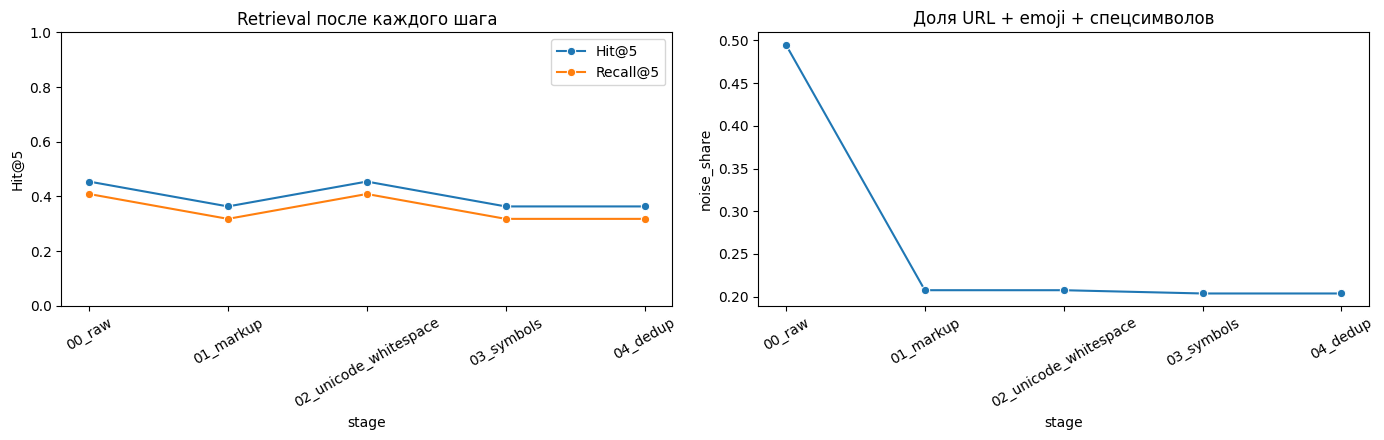

In [ ]:
# Визуализация эффекта предобработки по validation.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.lineplot(data=preprocessing_results, x="stage", y=f"Hit@{PRIMARY_K}", marker="o", ax=axes[0], label=f"Hit@{PRIMARY_K}")
sns.lineplot(data=preprocessing_results, x="stage", y=f"Recall@{PRIMARY_K}", marker="o", ax=axes[0], label=f"Recall@{PRIMARY_K}")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_ylim(0, 1)
axes[0].set_title("Retrieval после каждого шага")
sns.lineplot(data=preprocessing_results, x="stage", y="noise_share", marker="o", ax=axes[1])
axes[1].tick_params(axis="x", rotation=30)
axes[1].set_title("Доля URL + emoji + спецсимволов")
plt.tight_layout()
plt.savefig(OUT / "preprocessing_effect.png", dpi=160, bbox_inches="tight")
plt.show()

Сравнение четырёх стратегий Chonkie

In [ ]:
FINAL_STAGE = "04_dedup"
CHUNKER_NAMES = ["TokenChunker", "SentenceChunker"]

chunks_by_chunker = {"TokenChunker": token_chunks_by_stage[FINAL_STAGE]}
chunking_rows = []
chunking_metrics_long = []

for chunker_name in CHUNKER_NAMES:
    print("\n===", chunker_name, "===")
    if chunker_name == "TokenChunker":
        chunks = chunks_by_chunker[chunker_name]
        seconds = preprocessing_results.loc[
            preprocessing_results["stage"] == FINAL_STAGE, "chunking_seconds"
        ].iloc[0]
    else:
        chunks, seconds = chunk_documents(
            STAGES[FINAL_STAGE], FINAL_STAGE, chunker_name, max_docs=DEBUG_MAX_DOCS
        )
        chunks_by_chunker[chunker_name] = chunks

    metrics, _, alignment, negative_summary, _ = evaluate_retriever(
        chunks,
        [x for x in gold if x["split"] == "validation"],
        quote_transform=STAGE_QUOTE_TRANSFORMS[FINAL_STAGE],
        aliases=duplicate_aliases,
    )
    stats = chunk_statistics(chunks)
    primary = metrics.loc[metrics["k"] == PRIMARY_K].iloc[0].to_dict()
    chunking_rows.append({
        "chunker": chunker_name,
        **stats,
        "chunking_seconds": seconds,
        f"Hit@{PRIMARY_K}": primary["Hit@k"],
        f"Recall@{PRIMARY_K}": primary["Recall@k"],
        "aligned_evidence_share": primary["aligned_evidence_share"],
        "mean_best_evidence_coverage": primary["mean_best_evidence_coverage"],
        **negative_summary,
    })
    temp = metrics.copy()
    temp.insert(0, "chunker", chunker_name)
    chunking_metrics_long.append(temp)

chunking_results = pd.DataFrame(chunking_rows)
chunking_metrics_all_k = pd.concat(chunking_metrics_long, ignore_index=True)
chunking_results.to_csv(OUT / "chunking_results_validation.csv", index=False)
chunking_metrics_all_k.to_csv(OUT / "chunking_metrics_all_k_validation.csv", index=False)

display(chunking_results.style.format({
    "mean_tokens": "{:.1f}", "median_tokens": "{:.1f}", "std_tokens": "{:.1f}",
    "share_lt_50": "{:.2%}", "share_gt_500": "{:.2%}",
    "chunking_seconds": "{:.1f}", f"Hit@{PRIMARY_K}": "{:.3f}",
    f"Recall@{PRIMARY_K}": "{:.3f}", "aligned_evidence_share": "{:.2%}",
    "mean_best_evidence_coverage": "{:.3f}",
}))


=== TokenChunker ===

=== SentenceChunker ===
  SentenceChunker: 50/500 документов
  SentenceChunker: 100/500 документов
  SentenceChunker: 150/500 документов
  SentenceChunker: 200/500 документов
  SentenceChunker: 250/500 документов
  SentenceChunker: 300/500 документов
  SentenceChunker: 350/500 документов
  SentenceChunker: 400/500 документов
  SentenceChunker: 450/500 документов
  SentenceChunker: 500/500 документов


,chunker,chunks,mean_tokens,median_tokens,std_tokens,share_lt_50,share_gt_500,chunking_seconds,Hit@5,Recall@5,aligned_evidence_share,mean_best_evidence_coverage,negative_questions,negative_top1_mean,negative_top1_p95
0,TokenChunker,9618,497.3,512.0,71.6,0.86%,94.89%,8.5,0.364,0.318,94.12%,0.944,6,0.159040,0.204060
1,SentenceChunker,10965,436.7,456.0,76.3,0.67%,9.48%,12.8,0.455,0.409,94.12%,0.929,6,0.164729,0.205271


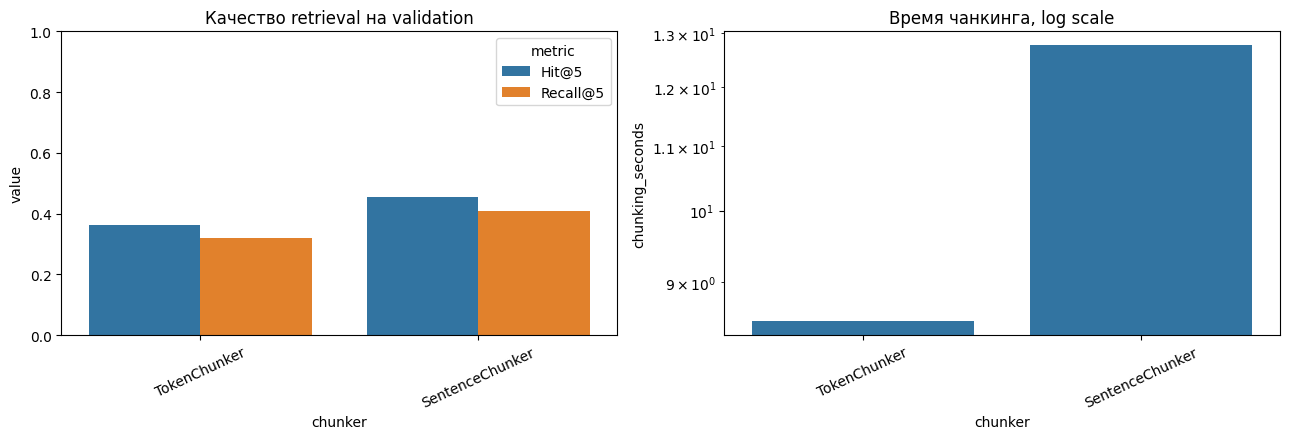

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_metrics = chunking_results.melt(
    id_vars="chunker", value_vars=[f"Hit@{PRIMARY_K}", f"Recall@{PRIMARY_K}"],
    var_name="metric", value_name="value"
)
sns.barplot(data=plot_metrics, x="chunker", y="value", hue="metric", ax=axes[0])
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=25)
axes[0].set_title("Качество retrieval на validation")
sns.barplot(data=chunking_results, x="chunker", y="chunking_seconds", ax=axes[1])
axes[1].tick_params(axis="x", rotation=25)
axes[1].set_yscale("log")
axes[1].set_title("Время чанкинга, log scale")
plt.tight_layout()
plt.savefig(OUT / "chunker_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

Детальный ablation: SemanticChunker

Загрузка основного эмбеддера: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/chonkie/embeddings/sentence_transformer.py:56: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self._dimension = self.model.get_sentence_embedding_dimension()


Batches:   0%|          | 0/79 [00:00<?, ?it/s]

,quantile,cosine_threshold
0,20%,0.295
1,40%,0.409
2,60%,0.509
3,80%,0.654


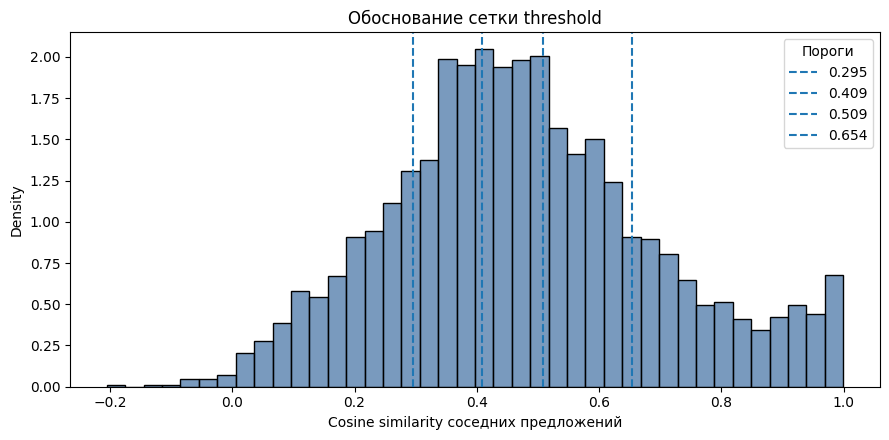

In [ ]:
import gc
import html
from IPython.display import HTML, display
from chonkie.embeddings import SentenceTransformerEmbeddings
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

ABLATION_STAGE = "04_dedup"
ABLATION_DOCS = STAGES[ABLATION_STAGE]
ABLATION_DEBUG_MAX_DOCS = None  # для итоговых метрик обязательно None
EMBEDDER_A = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
EMBEDDER_B = "sentence-transformers/distiluse-base-multilingual-cased-v2"
SIMILARITY_QUANTILES = (0.20, 0.40, 0.60, 0.80)
MAX_SIMILARITY_PAIRS = 5000


def sentences_for_grid(text):
    parts = re.split(r"(?<=[.!?])\s+|\n+", text)
    return [p.strip() for p in parts if len(p.strip()) >= 12]


def observed_adjacent_similarities(stage_docs, embedding, max_pairs=5000):
    sentences = []
    pair_indices = []
    for doc in sorted(stage_docs, key=lambda x: x["doc_id"]):
        current = sentences_for_grid(doc["text"])
        if len(current) < 2:
            continue
        start = len(sentences)
        sentences.extend(current)
        pair_indices.extend((start + i, start + i + 1) for i in range(len(current) - 1))
        if len(pair_indices) >= max_pairs:
            pair_indices = pair_indices[:max_pairs]
            max_used = max(j for pair in pair_indices for j in pair) + 1
            sentences = sentences[:max_used]
            break
    if not pair_indices:
        raise ValueError("Не удалось получить пары соседних предложений.")
    vectors = embedding.model.encode(
        sentences,
        batch_size=64,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )
    return np.asarray([
        float(np.dot(vectors[i], vectors[j])) for i, j in pair_indices
    ])


print("Загрузка основного эмбеддера:", EMBEDDER_A)
embedding_a =embedding_a = SentenceTransformerEmbeddings(
    EMBEDDER_A,
    device=DEVICE
)
adjacent_similarities = observed_adjacent_similarities(
    ABLATION_DOCS, embedding_a, MAX_SIMILARITY_PAIRS
)

THRESHOLD_GRID = sorted({
    round(float(x), 3)
    for x in np.quantile(adjacent_similarities, SIMILARITY_QUANTILES)
})
if len(THRESHOLD_GRID) < 3:
    raise ValueError(
        f"Квантили дали слишком мало уникальных порогов: {THRESHOLD_GRID}. "
        "Увеличьте MAX_SIMILARITY_PAIRS."
    )

grid_justification = pd.DataFrame({
    "quantile": SIMILARITY_QUANTILES,
    "cosine_threshold": np.quantile(adjacent_similarities, SIMILARITY_QUANTILES),
})
display(grid_justification.style.format({"quantile": "{:.0%}", "cosine_threshold": "{:.3f}"}))

plt.figure(figsize=(9, 4.5))
sns.histplot(adjacent_similarities, bins=40, stat="density", color="#4C78A8")
for threshold in THRESHOLD_GRID:
    plt.axvline(threshold, linestyle="--", label=f"{threshold:.3f}")
plt.xlabel("Cosine similarity соседних предложений")
plt.title("Обоснование сетки threshold")
plt.legend(title="Пороги")
plt.tight_layout()
plt.savefig(OUT / "semantic_threshold_grid.png", dpi=160, bbox_inches="tight")
plt.show()

In [ ]:
tokenizer = embedding_a.model.tokenizer
tokenizer_class = type(tokenizer)

if not hasattr(tokenizer, "batch_encode_plus"):

    def batch_encode_plus_compat(
        self,
        batch_text_or_text_pairs,
        **kwargs
    ):
        return self(
            list(batch_text_or_text_pairs),
            **kwargs
        )

    tokenizer_class.batch_encode_plus = batch_encode_plus_compat

print(
    "Tokenizer:", type(tokenizer).__name__,
    "| batch_encode_plus:", hasattr(tokenizer, "batch_encode_plus")
)

Tokenizer: TokenizersBackend | batch_encode_plus: True


In [ ]:
def semantic_chunker(embedding, threshold):
    return SemanticChunker(
        embedding_model=embedding,
        mode="window",
        threshold=float(threshold),
        chunk_size=CHUNK_SIZE,
        similarity_window=1,
        min_sentences=1,
        min_chunk_size=2,
        min_characters_per_sentence=12,
        delim=[". ", "! ", "? ", "\n"],
        include_delim="prev",
        return_type="chunks",
    )


def chunk_documents_with_instance(stage_docs, stage_name, config_name, chunker, max_docs=None):
    selected = stage_docs if max_docs is None else stage_docs[:max_docs]
    rows = []
    started = time.perf_counter()
    for doc_number, d in enumerate(selected):
        if not d["text"].strip():
            continue
        produced = chunker(d["text"])
        for chunk_index, chunk in enumerate(produced):
            chunk_text = str(getattr(chunk, "text", chunk))
            if not chunk_text.strip():
                continue
            start = int(getattr(chunk, "start_index", -1))
            end = int(getattr(chunk, "end_index", -1))
            token_count = int(getattr(chunk, "token_count", count_model_tokens(chunk_text)))
            raw_key = f"{stage_name}|{config_name}|{d['doc_id']}|{chunk_index}|{start}|{end}"
            rows.append({
                "chunk_id": sha256_text(raw_key)[:24],
                "doc_id": d["doc_id"], "parent_doc_id": d["doc_id"],
                "title": d["title"], "url": d["url"], "source": d["source"],
                "redirect": d["redirect"], "preprocessing_version": stage_name,
                "chunker": config_name, "chunk_index": chunk_index,
                "start_index": start, "end_index": end,
                "token_count": token_count, "text": chunk_text,
            })
        if (doc_number + 1) % 50 == 0:
            print(f"  {config_name}: {doc_number + 1}/{len(selected)} документов")
    return rows, time.perf_counter() - started


SEMANTIC_ABLATION_CHUNKS = globals().get("SEMANTIC_ABLATION_CHUNKS", {})
SEMANTIC_ABLATION_TIMES = globals().get("SEMANTIC_ABLATION_TIMES", {})
validation_gold = [x for x in gold if x["split"] == "validation"]

threshold_rows = []
threshold_metrics_long = []

for threshold in THRESHOLD_GRID:
    cache_key = (EMBEDDER_A, float(threshold))
    config_name = f"Semantic|A|cos={threshold:.3f}"
    print("\n===", config_name, "===")
    if cache_key not in SEMANTIC_ABLATION_CHUNKS:
        current_chunker = semantic_chunker(embedding_a, threshold)
        chunks, seconds = chunk_documents_with_instance(
            ABLATION_DOCS, ABLATION_STAGE, config_name, current_chunker,
            max_docs=ABLATION_DEBUG_MAX_DOCS,
        )
        SEMANTIC_ABLATION_CHUNKS[cache_key] = chunks
        SEMANTIC_ABLATION_TIMES[cache_key] = seconds
        del current_chunker
        gc.collect()
    chunks = SEMANTIC_ABLATION_CHUNKS[cache_key]
    metrics, _, alignment, negative_summary, _ = evaluate_retriever(
        chunks, validation_gold,
        quote_transform=STAGE_QUOTE_TRANSFORMS[ABLATION_STAGE],
        aliases=duplicate_aliases,
    )
    stats = chunk_statistics(chunks)
    primary = metrics.loc[metrics["k"] == PRIMARY_K].iloc[0]
    threshold_rows.append({
        "embedder": EMBEDDER_A,
        "threshold": float(threshold),
        **stats,
        "chunking_seconds": SEMANTIC_ABLATION_TIMES[cache_key],
        f"Hit@{PRIMARY_K}": primary["Hit@k"],
        f"Recall@{PRIMARY_K}": primary["Recall@k"],
        "aligned_evidence_share": primary["aligned_evidence_share"],
        "mean_best_evidence_coverage": primary["mean_best_evidence_coverage"],
        **negative_summary,
    })
    temp = metrics.copy()
    temp.insert(0, "embedder", EMBEDDER_A)
    temp.insert(1, "threshold", float(threshold))
    threshold_metrics_long.append(temp)

threshold_ablation = pd.DataFrame(threshold_rows).sort_values("threshold")
threshold_metrics_all_k = pd.concat(threshold_metrics_long, ignore_index=True)
threshold_ablation.to_csv(OUT / "semantic_threshold_ablation_validation.csv", index=False)
threshold_metrics_all_k.to_csv(OUT / "semantic_threshold_metrics_all_k_validation.csv", index=False)

display(threshold_ablation.style.format({
    "threshold": "{:.3f}", "mean_tokens": "{:.1f}", "median_tokens": "{:.1f}",
    "std_tokens": "{:.1f}", "share_lt_50": "{:.2%}", "share_gt_500": "{:.2%}",
    "chunking_seconds": "{:.1f}", f"Hit@{PRIMARY_K}": "{:.3f}",
    f"Recall@{PRIMARY_K}": "{:.3f}", "aligned_evidence_share": "{:.2%}",
    "mean_best_evidence_coverage": "{:.3f}",
}))


=== Semantic|A|cos=0.295 ===


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (129 > 128). Running this sequence through the model will result in indexing errors


  Semantic|A|cos=0.295: 50/500 документов
  Semantic|A|cos=0.295: 100/500 документов
  Semantic|A|cos=0.295: 150/500 документов
  Semantic|A|cos=0.295: 200/500 документов
  Semantic|A|cos=0.295: 250/500 документов
  Semantic|A|cos=0.295: 300/500 документов
  Semantic|A|cos=0.295: 350/500 документов
  Semantic|A|cos=0.295: 400/500 документов
  Semantic|A|cos=0.295: 450/500 документов
  Semantic|A|cos=0.295: 500/500 документов

=== Semantic|A|cos=0.409 ===
  Semantic|A|cos=0.409: 50/500 документов
  Semantic|A|cos=0.409: 100/500 документов
  Semantic|A|cos=0.409: 150/500 документов
  Semantic|A|cos=0.409: 200/500 документов
  Semantic|A|cos=0.409: 250/500 документов
  Semantic|A|cos=0.409: 300/500 документов
  Semantic|A|cos=0.409: 350/500 документов
  Semantic|A|cos=0.409: 400/500 документов
  Semantic|A|cos=0.409: 450/500 документов
  Semantic|A|cos=0.409: 500/500 документов

=== Semantic|A|cos=0.509 ===
  Semantic|A|cos=0.509: 50/500 документов
  Semantic|A|cos=0.509: 100/500 документ

,embedder,threshold,chunks,mean_tokens,median_tokens,std_tokens,share_lt_50,share_gt_500,chunking_seconds,Hit@5,Recall@5,aligned_evidence_share,mean_best_evidence_coverage,negative_questions,negative_top1_mean,negative_top1_p95
0,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,0.295,4114,434.9,474.0,110.6,2.77%,0.66%,130.3,0.636,0.455,94.12%,0.951,6,0.130656,0.202092
1,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,0.409,4353,411.1,471.0,136.0,4.76%,0.78%,137.3,0.545,0.409,94.12%,0.951,6,0.126457,0.189761
2,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,0.509,4903,364.9,463.0,168.1,9.14%,0.63%,136.7,0.455,0.409,94.12%,0.952,6,0.147513,0.245184
3,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,0.654,7180,249.2,214.0,189.3,22.42%,0.49%,136.6,0.273,0.273,94.12%,0.950,6,0.166484,0.226442


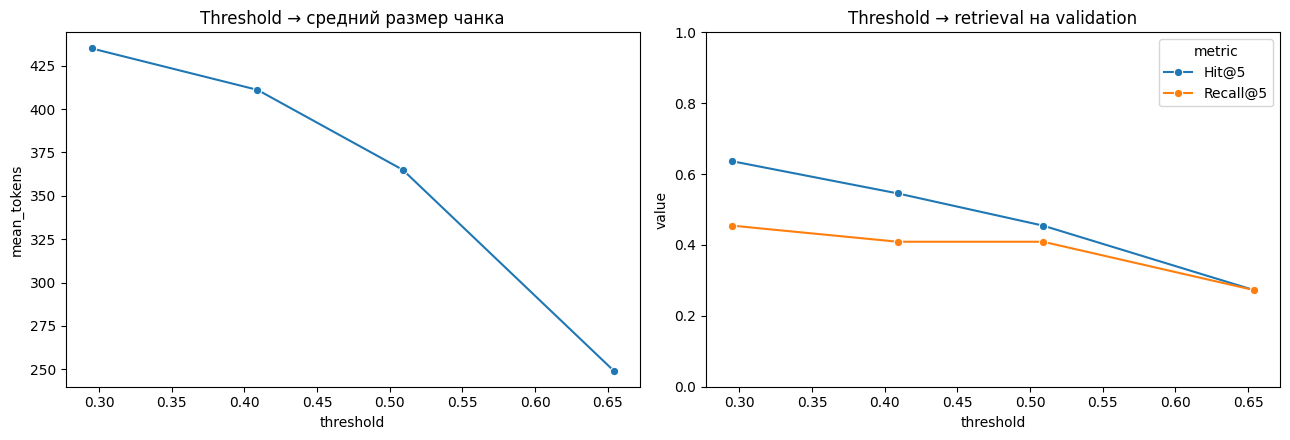

Предложенный threshold по validation: 0.295


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.lineplot(data=threshold_ablation, x="threshold", y="mean_tokens", marker="o", ax=axes[0])
axes[0].set_title("Threshold → средний размер чанка")
quality_long = threshold_ablation.melt(
    id_vars="threshold", value_vars=[f"Hit@{PRIMARY_K}", f"Recall@{PRIMARY_K}"],
    var_name="metric", value_name="value",
)
sns.lineplot(data=quality_long, x="threshold", y="value", hue="metric", marker="o", ax=axes[1])
axes[1].set_ylim(0, 1)
axes[1].set_title("Threshold → retrieval на validation")
plt.tight_layout()
plt.savefig(OUT / "semantic_threshold_ablation.png", dpi=160, bbox_inches="tight")
plt.show()

# Сначала Recall, затем Hit; при равенстве предпочитаем более высокое покрытие
# evidence и меньшую стоимость. Решение принимается только по validation.
BEST_THRESHOLD = float(
    threshold_ablation.sort_values(
        [f"Recall@{PRIMARY_K}", f"Hit@{PRIMARY_K}",
         "mean_best_evidence_coverage", "chunking_seconds"],
        ascending=[False, False, False, True],
    ).iloc[0]["threshold"]
)
print(f"Предложенный threshold по validation: {BEST_THRESHOLD:.3f}")

In [ ]:
EMBEDDERS = {
    "MiniLM-multilingual": EMBEDDER_A,
    "DistilUSE-multilingual": EMBEDDER_B,
}

embedding_instances = {"MiniLM-multilingual": embedding_a}
model_rows = []
model_metrics_long = []

for short_name, model_name in EMBEDDERS.items():
    print("\n===", short_name, f"threshold={BEST_THRESHOLD:.3f}", "===")
    cache_key = (model_name, BEST_THRESHOLD)
    config_name = f"Semantic|{short_name}|cos={BEST_THRESHOLD:.3f}"
    if cache_key not in SEMANTIC_ABLATION_CHUNKS:
        if short_name not in embedding_instances:
            embedding_instances[short_name] = SentenceTransformerEmbeddings(
    model_name,
    device=DEVICE
)
        current_chunker = semantic_chunker(embedding_instances[short_name], BEST_THRESHOLD)
        chunks, seconds = chunk_documents_with_instance(
            ABLATION_DOCS, ABLATION_STAGE, config_name, current_chunker,
            max_docs=ABLATION_DEBUG_MAX_DOCS,
        )
        SEMANTIC_ABLATION_CHUNKS[cache_key] = chunks
        SEMANTIC_ABLATION_TIMES[cache_key] = seconds
        del current_chunker
        gc.collect()
    chunks = SEMANTIC_ABLATION_CHUNKS[cache_key]
    metrics, _, alignment, negative_summary, _ = evaluate_retriever(
        chunks, validation_gold,
        quote_transform=STAGE_QUOTE_TRANSFORMS[ABLATION_STAGE],
        aliases=duplicate_aliases,
    )
    stats = chunk_statistics(chunks)
    primary = metrics.loc[metrics["k"] == PRIMARY_K].iloc[0]
    model_rows.append({
        "embedder_label": short_name, "embedder": model_name,
        "threshold": BEST_THRESHOLD, **stats,
        "chunking_seconds": SEMANTIC_ABLATION_TIMES[cache_key],
        f"Hit@{PRIMARY_K}": primary["Hit@k"],
        f"Recall@{PRIMARY_K}": primary["Recall@k"],
        "aligned_evidence_share": primary["aligned_evidence_share"],
        "mean_best_evidence_coverage": primary["mean_best_evidence_coverage"],
        **negative_summary,
    })
    temp = metrics.copy()
    temp.insert(0, "embedder_label", short_name)
    temp.insert(1, "embedder", model_name)
    temp.insert(2, "threshold", BEST_THRESHOLD)
    model_metrics_long.append(temp)

embedder_ablation = pd.DataFrame(model_rows)
embedder_metrics_all_k = pd.concat(model_metrics_long, ignore_index=True)


def internal_boundaries(chunks, stage_docs):
    lengths = {d["doc_id"]: len(d["text"]) for d in stage_docs}
    result = defaultdict(set)
    for chunk in chunks:
        end = chunk["end_index"]
        if 0 < end < lengths.get(chunk["doc_id"], 0):
            result[chunk["doc_id"]].add(end)
    return result


chunks_a = SEMANTIC_ABLATION_CHUNKS[(EMBEDDER_A, BEST_THRESHOLD)]
chunks_b = SEMANTIC_ABLATION_CHUNKS[(EMBEDDER_B, BEST_THRESHOLD)]
boundaries_a = internal_boundaries(chunks_a, ABLATION_DOCS)
boundaries_b = internal_boundaries(chunks_b, ABLATION_DOCS)
boundary_jaccards = []
for doc_id in {d["doc_id"] for d in ABLATION_DOCS}:
    a, b = boundaries_a[doc_id], boundaries_b[doc_id]
    boundary_jaccards.append(1.0 if not (a | b) else len(a & b) / len(a | b))

MEAN_BOUNDARY_JACCARD = float(np.mean(boundary_jaccards))
embedder_ablation["pairwise_mean_boundary_jaccard"] = MEAN_BOUNDARY_JACCARD
embedder_ablation.to_csv(OUT / "semantic_embedder_ablation_validation.csv", index=False)
embedder_metrics_all_k.to_csv(OUT / "semantic_embedder_metrics_all_k_validation.csv", index=False)

display(embedder_ablation.style.format({
    "threshold": "{:.3f}", "mean_tokens": "{:.1f}", "median_tokens": "{:.1f}",
    "std_tokens": "{:.1f}", "share_lt_50": "{:.2%}", "share_gt_500": "{:.2%}",
    "chunking_seconds": "{:.1f}", f"Hit@{PRIMARY_K}": "{:.3f}",
    f"Recall@{PRIMARY_K}": "{:.3f}", "aligned_evidence_share": "{:.2%}",
    "mean_best_evidence_coverage": "{:.3f}",
    "pairwise_mean_boundary_jaccard": "{:.3f}",
}))
print(f"Средний Jaccard внутренних границ двух моделей: {MEAN_BOUNDARY_JACCARD:.3f}")
BEST_EMBEDDER = str(
    embedder_ablation.sort_values(
        [f"Recall@{PRIMARY_K}", f"Hit@{PRIMARY_K}",
         "mean_best_evidence_coverage", "chunking_seconds"],
        ascending=[False, False, False, True],
    ).iloc[0]["embedder"]
)
print("Предложенный эмбеддер по validation:", BEST_EMBEDDER)


=== MiniLM-multilingual threshold=0.295 ===

=== DistilUSE-multilingual threshold=0.295 ===


modules.json:   0%|          | 0.00/341 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/2.46k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

2_Dense/model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/chonkie/embeddings/sentence_transformer.py:56: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self._dimension = self.model.get_sentence_embedding_dimension()
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (138 > 128). Running this sequence through the model will result in indexing errors


  Semantic|DistilUSE-multilingual|cos=0.295: 50/500 документов
  Semantic|DistilUSE-multilingual|cos=0.295: 100/500 документов
  Semantic|DistilUSE-multilingual|cos=0.295: 150/500 документов
  Semantic|DistilUSE-multilingual|cos=0.295: 200/500 документов
  Semantic|DistilUSE-multilingual|cos=0.295: 250/500 документов
  Semantic|DistilUSE-multilingual|cos=0.295: 300/500 документов
  Semantic|DistilUSE-multilingual|cos=0.295: 350/500 документов
  Semantic|DistilUSE-multilingual|cos=0.295: 400/500 документов
  Semantic|DistilUSE-multilingual|cos=0.295: 450/500 документов
  Semantic|DistilUSE-multilingual|cos=0.295: 500/500 документов


,embedder_label,embedder,threshold,chunks,mean_tokens,median_tokens,std_tokens,share_lt_50,share_gt_500,chunking_seconds,Hit@5,Recall@5,aligned_evidence_share,mean_best_evidence_coverage,negative_questions,negative_top1_mean,negative_top1_p95,pairwise_mean_boundary_jaccard
0,MiniLM-multilingual,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,0.295,4114,434.9,474.0,110.6,2.77%,0.66%,130.3,0.636,0.455,94.12%,0.951,6,0.130656,0.202092,0.304
1,DistilUSE-multilingual,sentence-transformers/distiluse-base-multilingual-cased-v2,0.295,4875,409.4,470.0,137.2,4.59%,1.37%,217.3,0.455,0.409,94.12%,0.931,6,0.172041,0.336970,0.304


Средний Jaccard внутренних границ двух моделей: 0.304
Предложенный эмбеддер по validation: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2


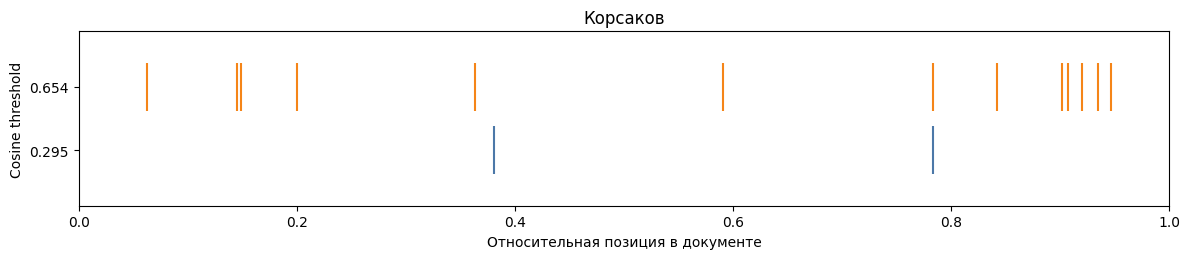

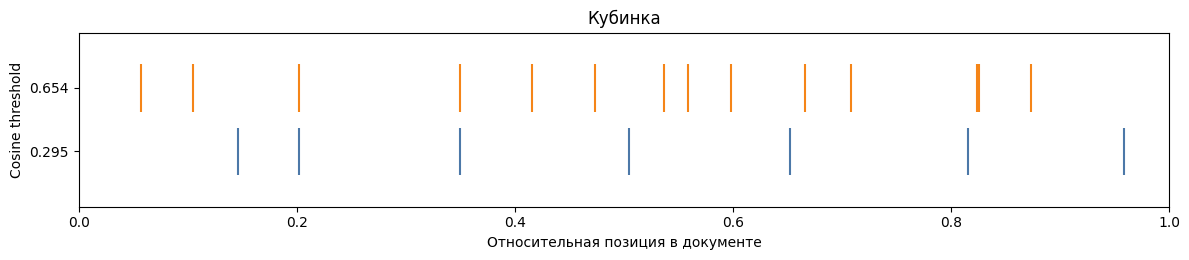

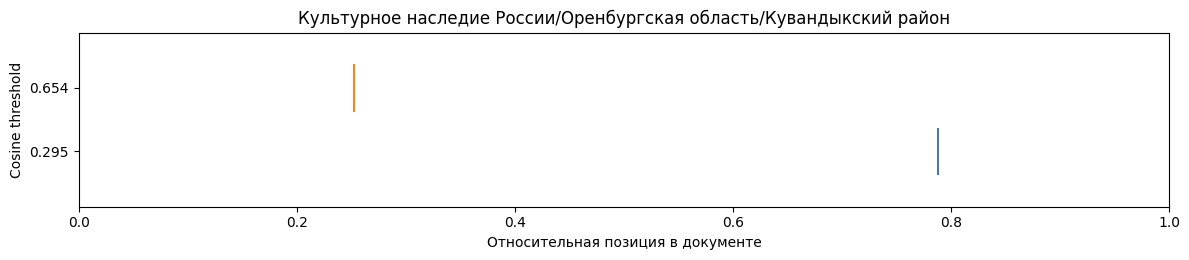

In [ ]:
VIS_THRESHOLDS = sorted({min(THRESHOLD_GRID), BEST_THRESHOLD, max(THRESHOLD_GRID)})
example_doc_ids = []
for row in validation_gold:
    if row["type"] == "negative":
        continue
    for evidence in row["evidence"]:
        doc_id = resolved_doc_id(str(evidence["doc_id"]), duplicate_aliases)
        if doc_id not in example_doc_ids and any(d["doc_id"] == doc_id for d in ABLATION_DOCS):
            example_doc_ids.append(doc_id)
        if len(example_doc_ids) >= 3:
            break
    if len(example_doc_ids) >= 3:
        break

doc_map_ablation = {d["doc_id"]: d for d in ABLATION_DOCS}
COLORS = ["#E8F1FB", "#FFF2CC", "#E2F0D9", "#FCE4D6", "#E4DFEC"]


def chunks_for_doc(threshold, doc_id):
    return [
        c for c in SEMANTIC_ABLATION_CHUNKS[(EMBEDDER_A, float(threshold))]
        if c["doc_id"] == doc_id
    ]


def show_colored_chunks(doc_id, thresholds, max_characters=2600):
    doc = doc_map_ablation[doc_id]
    sections = [f"<h3>{html.escape(doc['title'])}</h3>"]
    for threshold in thresholds:
        pieces = []
        for i, chunk in enumerate(chunks_for_doc(threshold, doc_id)):
            if chunk["start_index"] >= max_characters:
                break
            visible = chunk["text"][:max(0, max_characters - chunk["start_index"])]
            pieces.append(
                f"<span style='background:{COLORS[i % len(COLORS)]};"
                "padding:2px 4px;border-radius:3px;margin:1px'>"
                f"{html.escape(visible)}</span>"
            )
        sections.append(
            f"<div><b>cosine threshold = {threshold:.3f}</b> "
            f"({len(chunks_for_doc(threshold, doc_id))} чанков)</div>"
            f"<div style='line-height:1.8;margin-bottom:14px'>{''.join(pieces)}</div>"
        )
    display(HTML("".join(sections)))


for doc_id in example_doc_ids:
    doc = doc_map_ablation[doc_id]
    boundary_positions = []
    labels = []
    for threshold in VIS_THRESHOLDS:
        positions = [
            c["end_index"] / max(1, len(doc["text"]))
            for c in chunks_for_doc(threshold, doc_id)
            if 0 < c["end_index"] < len(doc["text"])
        ]
        boundary_positions.append(positions)
        labels.append(f"{threshold:.3f}")
    fig, ax = plt.subplots(figsize=(12, 2.7))
    ax.eventplot(boundary_positions, orientation="horizontal", lineoffsets=range(len(labels)),
                 linelengths=0.75, colors=["#4C78A8", "#F58518", "#54A24B"][:len(labels)])
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlim(0, 1)
    ax.set_xlabel("Относительная позиция в документе")
    ax.set_ylabel("Cosine threshold")
    ax.set_title(doc["title"])
    plt.tight_layout()
    plt.savefig(OUT / f"semantic_boundaries_{doc_id}.png", dpi=160, bbox_inches="tight")
    plt.show()
    show_colored_chunks(doc_id, VIS_THRESHOLDS)

ParentDocumentRetriever

In [ ]:
import torch
from sentence_transformers import SentenceTransformer

BGE_MODEL_NAME = "BAAI/bge-m3"
BGE_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BGE_BATCH_SIZE = 8 if BGE_DEVICE == "cuda" else 2
BGE_MAX_SEQ_LENGTH = 1024
PARENT_DEBUG_MAX_DOCS = None  # например 20 для smoke-test; перед отчётом вернуть None

if BGE_DEVICE != "cuda":
    print("ВНИМАНИЕ: GPU не найден. В Colab: Runtime → Change runtime type → T4 GPU.")
else:
    print("BGE-M3 будет работать на", torch.cuda.get_device_name(0))

if "bge_m3_model" not in globals():
    bge_m3_model = SentenceTransformer(BGE_MODEL_NAME, device=BGE_DEVICE)
bge_m3_model.max_seq_length = BGE_MAX_SEQ_LENGTH

PARENT_CONFIGS = [
    {"name": "P1024_C128", "parent_size": 1024, "parent_overlap": 128,
     "child_size": 128, "child_overlap": 16},
    {"name": "P1536_C256", "parent_size": 1536, "parent_overlap": 192,
     "child_size": 256, "child_overlap": 32},
    {"name": "P2048_C512", "parent_size": 2048, "parent_overlap": 256,
     "child_size": 512, "child_overlap": 64},
]


def _chunk_offsets(chunk, container_text, fallback_start=0):
    """Берёт точные offsets Chonkie; fallback нужен для старых версий."""
    text = str(getattr(chunk, "text", chunk))
    start = int(getattr(chunk, "start_index", -1))
    end = int(getattr(chunk, "end_index", -1))
    if start < 0 or end < start:
        start = container_text.find(text, max(0, fallback_start))
        if start < 0:
            start = container_text.find(text)
        start = max(0, start)
        end = start + len(text)
    return text, start, end


def build_parent_child_chunks(stage_docs, stage_name, config, max_docs=None):
    selected = stage_docs if max_docs is None else stage_docs[:max_docs]
    parent_chunker = TokenChunker(
        tokenizer="gpt2", chunk_size=config["parent_size"],
        chunk_overlap=config["parent_overlap"], return_type="chunks",
    )
    child_chunker = TokenChunker(
        tokenizer="gpt2", chunk_size=config["child_size"],
        chunk_overlap=config["child_overlap"], return_type="chunks",
    )
    parents, children = [], []
    started = time.perf_counter()

    for doc_number, d in enumerate(selected):
        if not d["text"].strip():
            continue
        parent_parts = parent_chunker(d["text"])
        parent_fallback = 0
        for parent_number, parent_part in enumerate(parent_parts):
            parent_text, parent_start, parent_end = _chunk_offsets(
                parent_part, d["text"], parent_fallback
            )
            parent_fallback = max(parent_start + 1, parent_end - 1)
            if not parent_text.strip():
                continue

            parent_id = sha256_text(
                f"{stage_name}|{config['name']}|parent|{d['doc_id']}|"
                f"{parent_number}|{parent_start}|{parent_end}"
            )[:24]
            parent_index = len(parents)
            parents.append({
                "chunk_id": parent_id,
                "parent_id": parent_id,
                "doc_id": d["doc_id"],
                "parent_doc_id": d["doc_id"],
                "title": d["title"], "url": d["url"], "source": d["source"],
                "redirect": d["redirect"], "preprocessing_version": stage_name,
                "chunker": f"ParentDocumentRetriever:{config['name']}",
                "chunk_index": parent_number,
                "start_index": parent_start, "end_index": parent_end,
                "token_count": int(getattr(
                    parent_part, "token_count", count_model_tokens(parent_text)
                )),
                "text": parent_text,
            })

            child_fallback = 0
            for child_number, child_part in enumerate(child_chunker(parent_text)):
                child_text, local_start, local_end = _chunk_offsets(
                    child_part, parent_text, child_fallback
                )
                child_fallback = max(local_start + 1, local_end - 1)
                if not child_text.strip():
                    continue
                global_start = parent_start + local_start
                global_end = parent_start + local_end
                child_id = sha256_text(
                    f"{parent_id}|child|{child_number}|{global_start}|{global_end}"
                )[:24]
                children.append({
                    "chunk_id": child_id,
                    "parent_id": parent_id,
                    "parent_index": parent_index,
                    "doc_id": d["doc_id"], "parent_doc_id": d["doc_id"],
                    "title": d["title"], "url": d["url"], "source": d["source"],
                    "redirect": d["redirect"], "preprocessing_version": stage_name,
                    "chunker": f"ParentDocumentRetriever:{config['name']}:child",
                    "chunk_index": child_number,
                    "start_index": global_start, "end_index": global_end,
                    "token_count": int(getattr(
                        child_part, "token_count", count_model_tokens(child_text)
                    )),
                    "text": child_text,
                })
        if (doc_number + 1) % 50 == 0:
            print(f"  {config['name']}: {doc_number + 1}/{len(selected)} документов")
    return parents, children, time.perf_counter() - started


def bge_cache_signature(items):
    ids = "|".join(str(x["chunk_id"]) for x in items)
    return sha256_text(f"{BGE_MODEL_NAME}|{BGE_MAX_SEQ_LENGTH}|{ids}")[:16]


def encode_bge_items(items, cache_prefix):
    """Нормализованные dense-векторы; dot product после этого равен cosine."""
    signature = bge_cache_signature(items)
    path = OUT / f"{cache_prefix}_{signature}.npy"
    if path.exists():
        vectors = np.load(path)
        if vectors.shape[0] == len(items):
            return vectors, 0.0, True

    texts = [f"{x['title']}\n{x['text']}" for x in items]
    started = time.perf_counter()
    vectors = bge_m3_model.encode(
        texts, batch_size=BGE_BATCH_SIZE, show_progress_bar=True,
        convert_to_numpy=True, normalize_embeddings=True,
    ).astype(np.float32, copy=False)
    seconds = time.perf_counter() - started
    np.save(path, vectors)
    return vectors, seconds, False


def encode_gold_questions(gold_records):
    ordered = sorted(gold_records, key=lambda x: x["candidate_id"])
    vectors = bge_m3_model.encode(
        [x["question"] for x in ordered], batch_size=BGE_BATCH_SIZE,
        show_progress_bar=False, convert_to_numpy=True, normalize_embeddings=True,
    ).astype(np.float32, copy=False)
    return {row["candidate_id"]: vectors[i] for i, row in enumerate(ordered)}


class DenseChunkRetriever:
    def __init__(self, vectors):
        self.vectors = vectors

    def search_vector(self, query_vector, k):
        scores = self.vectors @ query_vector
        k = min(k, len(scores))
        if k == 0:
            return []
        candidates = np.argpartition(-scores, k - 1)[:k]
        order = candidates[np.argsort(-scores[candidates], kind="stable")]
        return [(int(i), float(scores[i])) for i in order]


class ParentDenseRetriever:
    def __init__(self, child_vectors, children, parent_count):
        self.child_vectors = child_vectors
        self.child_to_parent = np.asarray(
            [x["parent_index"] for x in children], dtype=np.int64
        )
        self.parent_count = parent_count

    def search_vector(self, query_vector, k):
        child_scores = self.child_vectors @ query_vector
        parent_scores = np.full(self.parent_count, -np.inf, dtype=np.float32)
        # Один parent может иметь много children: оставляем лучший cosine score.
        np.maximum.at(parent_scores, self.child_to_parent, child_scores)
        k = min(k, len(parent_scores))
        if k == 0:
            return []
        candidates = np.argpartition(-parent_scores, k - 1)[:k]
        order = candidates[np.argsort(-parent_scores[candidates], kind="stable")]
        return [(int(i), float(parent_scores[i])) for i in order]


def evaluate_dense_retriever(
    retriever, context_chunks, gold_records, query_vectors,
    quote_transform, aliases=None, ks=KS,
):
    positives = [x for x in gold_records if x["type"] != "negative"]
    negatives = [x for x in gold_records if x["type"] == "negative"]
    if not positives:
        raise ValueError("В split нет положительных вопросов.")
    relevance, alignment = build_relevance_map(
        context_chunks, positives, quote_transform=quote_transform, aliases=aliases
    )
    per_query = []
    max_k = max(ks)
    for row in positives:
        ranked = retriever.search_vector(query_vectors[row["candidate_id"]], max_k)
        evidence_sets = relevance[row["candidate_id"]]
        for k in ks:
            retrieved = {idx for idx, _ in ranked[:k]}
            found = [bool(retrieved & relevant) for relevant in evidence_sets]
            per_query.append({
                "candidate_id": row["candidate_id"], "type": row["type"], "k": k,
                "hit": float(any(found)),
                "recall": sum(found) / max(1, len(found)),
            })
    per_query_df = pd.DataFrame(per_query)

    overall_rows = []
    for k in ks:
        part = per_query_df[per_query_df["k"] == k]
        overall_rows.append({
            "k": k, "positive_questions": len(positives),
            "Hit@k": part["hit"].mean(), "Recall@k": part["recall"].mean(),
            "aligned_evidence_share": alignment["aligned"].mean() if len(alignment) else math.nan,
            "mean_best_evidence_coverage": alignment["best_chunk_coverage"].mean()
            if len(alignment) else math.nan,
        })

    by_type = (
        per_query_df.groupby(["type", "k"], as_index=False)
        .agg(n_questions=("candidate_id", "nunique"),
             **{"Hit@k": ("hit", "mean"), "Recall@k": ("recall", "mean")})
        .rename(columns={"type": "question_type"})
    )
    negative_scores = []
    for row in negatives:
        found = retriever.search_vector(query_vectors[row["candidate_id"]], 1)
        negative_scores.append(found[0][1] if found else 0.0)
    negative_summary = {
        "negative_questions": len(negatives),
        "negative_top1_mean": float(np.mean(negative_scores)) if negative_scores else math.nan,
        "negative_top1_p95": float(np.quantile(negative_scores, 0.95))
        if negative_scores else math.nan,
    }
    return pd.DataFrame(overall_rows), by_type, per_query_df, alignment, negative_summary


BGE-M3 будет работать на Tesla T4


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

...

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

In [ ]:
validation_gold = [x for x in gold if x["split"] == "validation"]
BGE_QUERY_VECTORS = encode_gold_questions(gold)

best_simple_row = chunking_results.sort_values(
    [f"Recall@{PRIMARY_K}", f"Hit@{PRIMARY_K}", "aligned_evidence_share"],
    ascending=[False, False, False], kind="stable",
).iloc[0]
BEST_SIMPLE_CHUNKER = str(best_simple_row["chunker"])
BEST_SIMPLE_CHUNKS = chunks_by_chunker[BEST_SIMPLE_CHUNKER]

simple_vectors, simple_embedding_seconds, simple_from_cache = encode_bge_items(
    BEST_SIMPLE_CHUNKS, f"bge_simple_{BEST_SIMPLE_CHUNKER}"
)
BGE_SIMPLE_RETRIEVER = DenseChunkRetriever(simple_vectors)
(
    bge_simple_metrics, bge_simple_by_type, bge_simple_queries,
    bge_simple_alignment, bge_simple_negative,
) = evaluate_dense_retriever(
    BGE_SIMPLE_RETRIEVER, BEST_SIMPLE_CHUNKS, validation_gold, BGE_QUERY_VECTORS,
    quote_transform=STAGE_QUOTE_TRANSFORMS[FINAL_STAGE], aliases=duplicate_aliases,
)

print("Простой BGE-M3 baseline:", BEST_SIMPLE_CHUNKER)
display(bge_simple_metrics.style.format({
    "Hit@k": "{:.3f}", "Recall@k": "{:.3f}",
    "aligned_evidence_share": "{:.2%}", "mean_best_evidence_coverage": "{:.3f}",
}))
display(bge_simple_by_type.style.format({"Hit@k": "{:.3f}", "Recall@k": "{:.3f}"}))

bge_simple_metrics.to_csv(OUT / "bge_simple_baseline_validation.csv", index=False)
bge_simple_by_type.to_csv(OUT / "bge_simple_baseline_by_type_validation.csv", index=False)


Batches:   0%|          | 0/1371 [00:00<?, ?it/s]

Простой BGE-M3 baseline: SentenceChunker


,k,positive_questions,Hit@k,Recall@k,aligned_evidence_share,mean_best_evidence_coverage
0,1,11,0.545,0.409,94.12%,0.929
1,3,11,0.636,0.545,94.12%,0.929
2,5,11,0.727,0.591,94.12%,0.929
3,10,11,0.727,0.636,94.12%,0.929


,question_type,k,n_questions,Hit@k,Recall@k
0,abstract,1,3,0.667,0.333
1,abstract,3,3,0.667,0.333
2,abstract,5,3,0.667,0.333
3,abstract,10,3,0.667,0.500
4,composite,1,3,0.333,0.167
5,composite,3,3,0.333,0.333
6,composite,5,3,0.667,0.500
7,composite,10,3,0.667,0.500
8,factual,1,5,0.600,0.600
9,factual,3,5,0.800,0.800


In [ ]:
PARENT_RUNS = {}
parent_result_rows = []
parent_metrics_long = []
parent_by_type_long = []

for config in PARENT_CONFIGS:
    print("\n===", config["name"], "===")
    parents, children, chunking_seconds = build_parent_child_chunks(
        STAGES[FINAL_STAGE], FINAL_STAGE, config, max_docs=PARENT_DEBUG_MAX_DOCS
    )
    child_vectors, embedding_seconds, from_cache = encode_bge_items(
        children, f"bge_children_{config['name']}"
    )
    retriever = ParentDenseRetriever(child_vectors, children, len(parents))
    metrics, by_type, per_query, alignment, negative = evaluate_dense_retriever(
        retriever, parents, validation_gold, BGE_QUERY_VECTORS,
        quote_transform=STAGE_QUOTE_TRANSFORMS[FINAL_STAGE], aliases=duplicate_aliases,
    )
    parent_stats = chunk_statistics(parents)
    child_stats = chunk_statistics(children)
    primary = metrics.loc[metrics["k"] == PRIMARY_K].iloc[0]
    parent_result_rows.append({
        "config": config["name"],
        "parent_size": config["parent_size"], "parent_overlap": config["parent_overlap"],
        "child_size": config["child_size"], "child_overlap": config["child_overlap"],
        "parents": len(parents), "children": len(children),
        "mean_parent_tokens": parent_stats["mean_tokens"],
        "median_parent_tokens": parent_stats["median_tokens"],
        "mean_child_tokens": child_stats["mean_tokens"],
        "median_child_tokens": child_stats["median_tokens"],
        "children_per_parent": len(children) / max(1, len(parents)),
        "chunking_seconds": chunking_seconds,
        "embedding_seconds": embedding_seconds,
        "embeddings_from_cache": from_cache,
        f"Hit@{PRIMARY_K}": primary["Hit@k"],
        f"Recall@{PRIMARY_K}": primary["Recall@k"],
        "aligned_evidence_share": primary["aligned_evidence_share"],
        "mean_best_evidence_coverage": primary["mean_best_evidence_coverage"],
        **negative,
    })
    metrics.insert(0, "config", config["name"])
    by_type.insert(0, "config", config["name"])
    parent_metrics_long.append(metrics)
    parent_by_type_long.append(by_type)
    PARENT_RUNS[config["name"]] = {
        "config": config, "parents": parents, "children": children,
        "child_vectors": child_vectors, "retriever": retriever,
        "metrics": metrics, "by_type": by_type, "per_query": per_query,
        "alignment": alignment, "negative": negative,
    }

parent_document_results = pd.DataFrame(parent_result_rows)
parent_document_metrics_all_k = pd.concat(parent_metrics_long, ignore_index=True)
parent_document_by_type = pd.concat(parent_by_type_long, ignore_index=True)

parent_document_results.to_csv(
    OUT / "parent_document_results_validation.csv", index=False
)
parent_document_metrics_all_k.to_csv(
    OUT / "parent_document_metrics_all_k_validation.csv", index=False
)
parent_document_by_type.to_csv(
    OUT / "parent_document_metrics_by_type_validation.csv", index=False
)

display(parent_document_results.style.format({
    "mean_parent_tokens": "{:.1f}", "median_parent_tokens": "{:.1f}",
    "mean_child_tokens": "{:.1f}", "median_child_tokens": "{:.1f}",
    "children_per_parent": "{:.1f}", "chunking_seconds": "{:.1f}",
    "embedding_seconds": "{:.1f}", f"Hit@{PRIMARY_K}": "{:.3f}",
    f"Recall@{PRIMARY_K}": "{:.3f}", "aligned_evidence_share": "{:.2%}",
    "mean_best_evidence_coverage": "{:.3f}",
}))



=== P1024_C128 ===
  P1024_C128: 50/500 документов
  P1024_C128: 100/500 документов
  P1024_C128: 150/500 документов
  P1024_C128: 200/500 документов
  P1024_C128: 250/500 документов
  P1024_C128: 300/500 документов
  P1024_C128: 350/500 документов
  P1024_C128: 400/500 документов
  P1024_C128: 450/500 документов
  P1024_C128: 500/500 документов


Batches:   0%|          | 0/6018 [00:00<?, ?it/s]


=== P1536_C256 ===
  P1536_C256: 50/500 документов
  P1536_C256: 100/500 документов
  P1536_C256: 150/500 документов
  P1536_C256: 200/500 документов
  P1536_C256: 250/500 документов
  P1536_C256: 300/500 документов
  P1536_C256: 350/500 документов
  P1536_C256: 400/500 документов
  P1536_C256: 450/500 документов
  P1536_C256: 500/500 документов


Batches:   0%|          | 0/3105 [00:00<?, ?it/s]


=== P2048_C512 ===
  P2048_C512: 50/500 документов
  P2048_C512: 100/500 документов
  P2048_C512: 150/500 документов
  P2048_C512: 200/500 документов
  P2048_C512: 250/500 документов
  P2048_C512: 300/500 документов
  P2048_C512: 350/500 документов
  P2048_C512: 400/500 документов
  P2048_C512: 450/500 документов
  P2048_C512: 500/500 документов


Batches:   0%|          | 0/1662 [00:00<?, ?it/s]

,config,parent_size,parent_overlap,child_size,child_overlap,parents,children,mean_parent_tokens,median_parent_tokens,mean_child_tokens,median_child_tokens,children_per_parent,chunking_seconds,embedding_seconds,embeddings_from_cache,Hit@5,Recall@5,aligned_evidence_share,mean_best_evidence_coverage,negative_questions,negative_top1_mean,negative_top1_p95
0,P1024_C128,1024,128,128,16,5570,48140,975.3,1024.0,127.0,128.0,8.6,20.7,737.4,False,0.727,0.636,94.12%,0.950,6,0.596742,0.710628
1,P1536_C256,1536,192,256,32,3777,24833,1433.0,1536.0,245.1,256.0,6.6,20.4,621.5,False,0.818,0.682,94.12%,0.951,6,0.586446,0.694899
2,P2048_C512,2048,256,512,64,2906,13295,1858.0,2048.0,456.1,512.0,4.6,21.0,569.5,False,0.818,0.727,94.12%,0.952,6,0.580399,0.653071


In [ ]:
simple_k = bge_simple_by_type[bge_simple_by_type["k"] == PRIMARY_K].copy()
simple_k = simple_k.rename(columns={
    "Hit@k": "simple_hit", "Recall@k": "simple_recall",
    "n_questions": "n_questions_simple",
})

comparison_rows = []
for config_name, run in PARENT_RUNS.items():
    parent_k = run["by_type"][run["by_type"]["k"] == PRIMARY_K]
    merged = parent_k.merge(
        simple_k[["question_type", "n_questions_simple", "simple_hit", "simple_recall"]],
        on="question_type", how="left",
    )
    for _, row in merged.iterrows():
        comparison_rows.append({
            "config": config_name, "question_type": row["question_type"],
            "n_questions": int(row["n_questions"]),
            "simple_hit": row["simple_hit"], "parent_hit": row["Hit@k"],
            "delta_hit": row["Hit@k"] - row["simple_hit"],
            "simple_recall": row["simple_recall"], "parent_recall": row["Recall@k"],
            "delta_recall": row["Recall@k"] - row["simple_recall"],
        })

parent_vs_simple_by_type = pd.DataFrame(comparison_rows)
parent_vs_simple_by_type.to_csv(
    OUT / "parent_document_vs_simple_by_type_validation.csv", index=False
)
display(parent_vs_simple_by_type.style.format({
    "simple_hit": "{:.3f}", "parent_hit": "{:.3f}", "delta_hit": "{:+.3f}",
    "simple_recall": "{:.3f}", "parent_recall": "{:.3f}",
    "delta_recall": "{:+.3f}",
}).background_gradient(subset=["delta_recall"], cmap="RdYlGn", vmin=-0.3, vmax=0.3))

BEST_PARENT_CONFIG = str(parent_document_results.sort_values(
    [f"Recall@{PRIMARY_K}", f"Hit@{PRIMARY_K}", "aligned_evidence_share"],
    ascending=[False, False, False], kind="stable",
).iloc[0]["config"])

print("\nЛучшая parent/child-конфигурация по validation:", BEST_PARENT_CONFIG)
best_comparison = parent_vs_simple_by_type[
    parent_vs_simple_by_type["config"] == BEST_PARENT_CONFIG
]
explanations = {
    "factual": "маленький child точнее локализует факт, а parent возвращает окружающий контекст",
    "composite": "выигрыш возможен, если разные evidence подняты разными children; один parent не объединяет разные документы",
    "abstract": "широкий parent сохраняет тему и связи, которые простой короткий чанк мог обрезать",
}
for _, row in best_comparison.sort_values("question_type").iterrows():
    relation = "выигрывает" if row["delta_recall"] > 0 else (
        "проигрывает" if row["delta_recall"] < 0 else "не отличается"
    )
    why = explanations.get(row["question_type"], "эффект зависит от расположения evidence")
    print(
        f"- {row['question_type']}: {relation} по Recall@{PRIMARY_K} "
        f"({row['simple_recall']:.3f} → {row['parent_recall']:.3f}, "
        f"Δ={row['delta_recall']:+.3f}; n={int(row['n_questions'])}). Почему: {why}."
    )


,config,question_type,n_questions,simple_hit,parent_hit,delta_hit,simple_recall,parent_recall,delta_recall
0,P1024_C128,abstract,3,0.667,0.667,+0.000,0.333,0.500,+0.167
1,P1024_C128,composite,3,0.667,0.667,+0.000,0.500,0.500,+0.000
2,P1024_C128,factual,5,0.800,0.800,+0.000,0.800,0.800,+0.000
3,P1536_C256,abstract,3,0.667,0.667,+0.000,0.333,0.500,+0.167
4,P1536_C256,composite,3,0.667,1.000,+0.333,0.500,0.667,+0.167
5,P1536_C256,factual,5,0.800,0.800,+0.000,0.800,0.800,+0.000
6,P2048_C512,abstract,3,0.667,0.667,+0.000,0.333,0.667,+0.333
7,P2048_C512,composite,3,0.667,1.000,+0.333,0.500,0.667,+0.167
8,P2048_C512,factual,5,0.800,0.800,+0.000,0.800,0.800,+0.000



Лучшая parent/child-конфигурация по validation: P2048_C512
- abstract: выигрывает по Recall@5 (0.333 → 0.667, Δ=+0.333; n=3). Почему: широкий parent сохраняет тему и связи, которые простой короткий чанк мог обрезать.
- composite: выигрывает по Recall@5 (0.500 → 0.667, Δ=+0.167; n=3). Почему: выигрыш возможен, если разные evidence подняты разными children; один parent не объединяет разные документы.
- factual: не отличается по Recall@5 (0.800 → 0.800, Δ=+0.000; n=5). Почему: маленький child точнее локализует факт, а parent возвращает окружающий контекст.


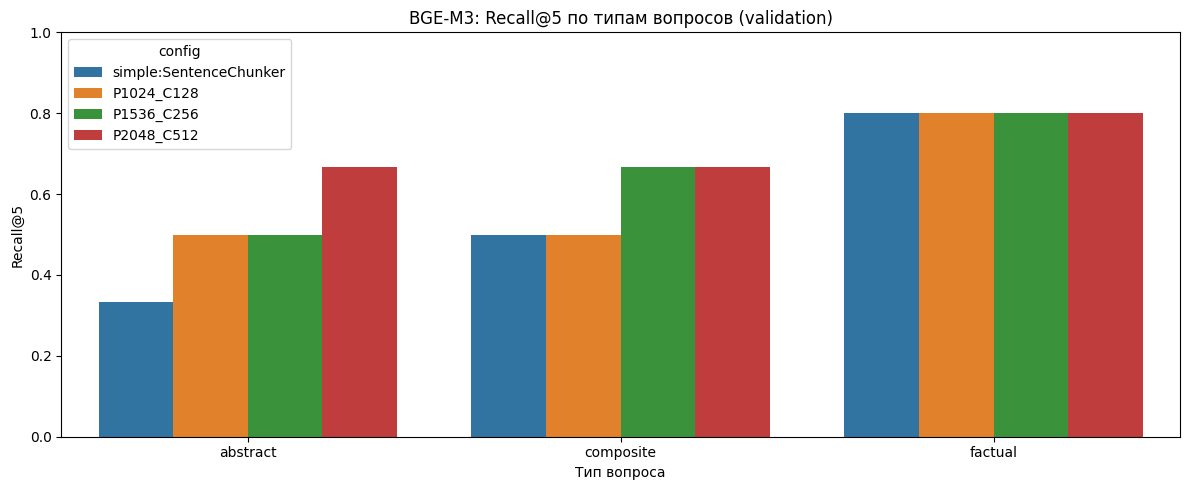

In [ ]:
plot_parent = parent_document_by_type[
    parent_document_by_type["k"] == PRIMARY_K
][["config", "question_type", "Recall@k"]].copy()
plot_simple = simple_k[["question_type", "simple_recall"]].copy()
plot_simple["config"] = f"simple:{BEST_SIMPLE_CHUNKER}"
plot_simple = plot_simple.rename(columns={"simple_recall": "Recall@k"})
plot_parent = pd.concat(
    [plot_simple[["config", "question_type", "Recall@k"]], plot_parent],
    ignore_index=True,
)

plt.figure(figsize=(12, 5))
sns.barplot(data=plot_parent, x="question_type", y="Recall@k", hue="config")
plt.ylim(0, 1)
plt.title(f"BGE-M3: Recall@{PRIMARY_K} по типам вопросов (validation)")
plt.xlabel("Тип вопроса")
plt.ylabel(f"Recall@{PRIMARY_K}")
plt.tight_layout()
plt.savefig(OUT / "parent_document_recall_by_type.png", dpi=160, bbox_inches="tight")
plt.show()


Метаданные: извлечение и проверка пользы

структурные: published_at, source, длина документа, номер и относительная позиция чанка;
контентные: top-5 TF-IDF keywords, язык, тип контента;
качественные: noise_score

In [ ]:
EDGE_PUNCTUATION = ".,!?;:\"'()[]{}<>«»…—–_*/\\|=+№#@$%^&~`"
RUSSIAN_STOP_WORDS = {
    "и", "в", "во", "не", "что", "он", "на", "я", "с", "со", "как", "а",
    "то", "все", "она", "так", "его", "но", "да", "ты", "к", "у", "же",
    "вы", "за", "бы", "по", "только", "ее", "мне", "было", "вот", "от",
    "меня", "еще", "нет", "о", "из", "ему", "теперь", "когда", "даже",
    "ну", "ли", "если", "или", "ни", "быть", "был", "него", "до", "вас",
    "нибудь", "опять", "уж", "вам", "ведь", "там", "потом", "себя", "ничего",
    "ей", "может", "они", "тут", "где", "есть", "надо", "ней", "для", "мы",
    "тебя", "их", "чем", "была", "сам", "чтоб", "без", "будто", "чего",
    "раз", "тоже", "себе", "под", "будет", "ж", "тогда", "кто", "этот",
    "того", "потому", "этого", "какой", "совсем", "ним", "здесь", "этом",
    "один", "почти", "мой", "тем", "чтобы", "нее", "сейчас", "были", "куда",
    "зачем", "сказать", "всех", "никогда", "сегодня", "можно", "при", "об",
    "другой", "хоть", "после", "над", "больше", "тот", "через", "эти", "нас",
    "про", "всего", "них", "какая", "много", "разве", "три", "эту", "моя",
    "впрочем", "хорошо", "свою", "этой", "перед", "иногда", "лучше", "чуть",
    "том", "нельзя", "такой", "им", "более", "всегда", "конечно", "всю",
    "между", "это", "также", "которые", "который", "которая", "которое",
}


def normalize_publication_date(value):
    if value in (None, ""):
        return None
    parsed = pd.to_datetime(value, errors="coerce", utc=True)
    return None if pd.isna(parsed) else parsed.isoformat()


def detect_chunk_language(text, hint=None):
    if hint:
        normalized = str(hint).strip().lower()
        return {"rus": "ru", "russian": "ru", "eng": "en", "english": "en"}.get(
            normalized, normalized
        )
    letters = [ch.lower() for ch in text if ch.isalpha()]
    if not letters:
        return "unknown"
    cyrillic = sum("а" <= ch <= "я" or ch == "ё" for ch in letters)
    latin = sum("a" <= ch <= "z" for ch in letters)
    cyr_share, lat_share = cyrillic / len(letters), latin / len(letters)
    if cyr_share >= 0.80:
        return "ru"
    if lat_share >= 0.80:
        return "en"
    if cyr_share >= 0.15 and lat_share >= 0.15:
        return "mixed_ru_en"
    return "other"


def infer_content_type(doc):
    if doc.get("content_type_hint"):
        return str(doc["content_type_hint"])
    title = doc["title"].lower()
    if doc.get("redirect") or title.startswith("перенаправление"):
        return "redirect"
    if title.startswith("культурное наследие россии/"):
        return "cultural_heritage_registry"
    if title.startswith("природные памятники россии/"):
        return "natural_monuments_registry"
    return "travel_guide"


def nonalphabetic_token_share(text):
    tokens = re.findall(r"\S+", text)
    if not tokens:
        return 0.0
    nonalphabetic = 0
    for token in tokens:
        core = token.strip(EDGE_PUNCTUATION)
        is_word = bool(core) and all(ch.isalpha() or ch in "-'’" for ch in core)
        nonalphabetic += not is_word
    return nonalphabetic / len(tokens)


def extract_tfidf_keywords(chunks, top_n=5):
    # Для двух тестовых чанков max_df=0.98 допускает только df<=1.
    min_df = 2 if len(chunks) >= 3 else 1
    vectorizer = TfidfVectorizer(
        lowercase=True, token_pattern=r"(?u)\b[а-яёa-z][а-яёa-z-]{2,}\b",
        stop_words=sorted(RUSSIAN_STOP_WORDS), min_df=min_df, max_df=0.98,
        max_features=30_000, sublinear_tf=True, dtype=np.float32,
    )
    matrix = vectorizer.fit_transform([x["text"] for x in chunks])
    terms = vectorizer.get_feature_names_out()
    keywords = []
    for row_number in range(matrix.shape[0]):
        row = matrix.getrow(row_number)
        ranked = sorted(
            zip(row.indices, row.data), key=lambda pair: (-pair[1], terms[pair[0]])
        )[:top_n]
        keywords.append([str(terms[index]) for index, _ in ranked])
    return keywords


def enrich_chunks_with_metadata(chunks, stage_docs):
    doc_map = {x["doc_id"]: x for x in stage_docs}
    chunks_per_doc = Counter(x["doc_id"] for x in chunks)
    doc_token_counts = {
        doc_id: count_model_tokens(doc["text"]) for doc_id, doc in doc_map.items()
    }
    keywords = extract_tfidf_keywords(chunks, top_n=5)
    enriched = []
    for chunk, top_keywords in zip(chunks, keywords):
        doc = doc_map[chunk["doc_id"]]
        count = chunks_per_doc[chunk["doc_id"]]
        position = chunk["chunk_index"] / max(1, count - 1)
        if count == 1:
            position_bucket = "whole_document"
        elif position < 1 / 3:
            position_bucket = "beginning"
        elif position < 2 / 3:
            position_bucket = "middle"
        else:
            position_bucket = "end"
        enriched.append({
            **chunk,
            "published_at": normalize_publication_date(doc.get("published_at")),
            "document_char_count": len(doc["text"]),
            "document_token_count": doc_token_counts[chunk["doc_id"]],
            "chunks_in_document": count,
            "relative_chunk_position": float(position),
            "position_bucket": position_bucket,
            "keywords": top_keywords,
            "language": detect_chunk_language(chunk["text"], doc.get("language_hint")),
            "content_type": infer_content_type(doc),
            "noise_score": nonalphabetic_token_share(chunk["text"]),
        })
    return enriched

METADATA_CHUNKS = enrich_chunks_with_metadata(BEST_SIMPLE_CHUNKS, STAGES[FINAL_STAGE])

metadata_path = OUT / "chunks_with_metadata.jsonl"
with metadata_path.open("w", encoding="utf-8") as f:
    for chunk in METADATA_CHUNKS:
        f.write(json.dumps(chunk, ensure_ascii=False) + "\n")

metadata_coverage = pd.DataFrame([
    {"metadata": "published_at", "coverage": np.mean([x["published_at"] is not None for x in METADATA_CHUNKS])},
    {"metadata": "source", "coverage": np.mean([bool(x["source"]) for x in METADATA_CHUNKS])},
    {"metadata": "keywords_top5", "coverage": np.mean([len(x["keywords"]) == 5 for x in METADATA_CHUNKS])},
    {"metadata": "language", "coverage": np.mean([x["language"] != "unknown" for x in METADATA_CHUNKS])},
    {"metadata": "content_type", "coverage": np.mean([bool(x["content_type"]) for x in METADATA_CHUNKS])},
    {"metadata": "noise_score", "coverage": np.mean([x["noise_score"] is not None for x in METADATA_CHUNKS])},
])
metadata_coverage.to_csv(OUT / "metadata_coverage.csv", index=False)

print("Распределение source:", Counter(x["source"] for x in METADATA_CHUNKS))
print("Распределение language:", Counter(x["language"] for x in METADATA_CHUNKS))
print("Распределение content_type:", Counter(x["content_type"] for x in METADATA_CHUNKS))
display(metadata_coverage.style.format({"coverage": "{:.1%}"}))
display(pd.DataFrame(METADATA_CHUNKS)[[
    "title", "published_at", "source", "document_token_count", "chunk_index",
    "relative_chunk_position", "keywords", "language", "content_type", "noise_score",
]].head(10).style.format({"relative_chunk_position": "{:.2f}", "noise_score": "{:.2%}"}))


Распределение source: Counter({'ruwikivoyage': 10965})
Распределение language: Counter({'ru': 6567, 'mixed_ru_en': 4380, 'other': 15, 'en': 3})
Распределение content_type: Counter({'cultural_heritage_registry': 5664, 'travel_guide': 4955, 'natural_monuments_registry': 282, 'redirect': 64})


,metadata,coverage
0,published_at,0.0%
1,source,100.0%
2,keywords_top5,99.2%
3,language,100.0%
4,content_type,100.0%
5,noise_score,100.0%


,title,published_at,source,document_token_count,chunk_index,relative_chunk_position,keywords,language,content_type,noise_score
0,Культурное наследие России/Оренбургская область/Орск,None,ruwikivoyage,12423,0,0.00,"['орск', 'orsk', 'базарная', 'ru-ore', 'организатор']",mixed_ru_en,cultural_heritage_registry,37.36%
1,Культурное наследие России/Оренбургская область/Орск,None,ruwikivoyage,12423,1,0.04,"['орск', 'маца', 'декабристов', 'ru-ore', 'гильдии']",mixed_ru_en,cultural_heritage_registry,36.27%
2,Культурное наследие России/Оренбургская область/Орск,None,ruwikivoyage,12423,2,0.07,"['орск', 'партийная', 'волкова', 'купца', 'создана']",mixed_ru_en,cultural_heritage_registry,34.07%
3,Культурное наследие России/Оренбургская область/Орск,None,ruwikivoyage,12423,3,0.11,"['орск', 'разина', 'степана', 'литвака', 'аптеки']",mixed_ru_en,cultural_heritage_registry,32.63%
4,Культурное наследие России/Оренбургская область/Орск,None,ruwikivoyage,12423,4,0.15,"['орск', 'marx', 'karl', 'джалиль', 'orsk']",mixed_ru_en,cultural_heritage_registry,29.47%
5,Культурное наследие России/Оренбургская область/Орск,None,ruwikivoyage,12423,5,0.19,"['герои', 'учились', 'орск', 'авдеев', 'сорокин']",ru,cultural_heritage_registry,28.77%
6,Культурное наследие России/Оренбургская область/Орск,None,ruwikivoyage,12423,6,0.22,"['куйбышева', 'орск', 'orsk', 'джалиль', 'созыва']",mixed_ru_en,cultural_heritage_registry,32.10%
7,Культурное наследие России/Оренбургская область/Орск,None,ruwikivoyage,12423,7,0.26,"['орск', 'льва', 'толстого', 'купцов', 'orsk']",mixed_ru_en,cultural_heritage_registry,31.87%
8,Культурное наследие России/Оренбургская область/Орск,None,ruwikivoyage,12423,8,0.30,"['орска', 'госпиталях', 'ран', 'умерших', 'orsk']",mixed_ru_en,cultural_heritage_registry,17.91%
9,Культурное наследие России/Оренбургская область/Орск,None,ruwikivoyage,12423,9,0.33,"['орск', 'станиславского', 'проспекта', 'мира', 'ru-ore']",mixed_ru_en,cultural_heritage_registry,38.20%


фильтрация по метаданным

In [ ]:
QUALITY_KEEP_QUANTILE = 0.90
QUALITY_NOISE_THRESHOLD = float(np.quantile(
    [x["noise_score"] for x in METADATA_CHUNKS], QUALITY_KEEP_QUANTILE
))
quality_keep_indices = [
    i for i, chunk in enumerate(METADATA_CHUNKS)
    if chunk["noise_score"] <= QUALITY_NOISE_THRESHOLD
]
QUALITY_FILTERED_CHUNKS = [METADATA_CHUNKS[i] for i in quality_keep_indices]
quality_filtered_vectors = simple_vectors[np.asarray(quality_keep_indices, dtype=int)]

METADATA_BASELINE_RETRIEVER = DenseChunkRetriever(simple_vectors)
QUALITY_FILTERED_RETRIEVER = DenseChunkRetriever(quality_filtered_vectors)

(
    metadata_baseline_metrics, metadata_baseline_by_type, metadata_baseline_queries,
    metadata_baseline_alignment, metadata_baseline_negative,
) = evaluate_dense_retriever(
    METADATA_BASELINE_RETRIEVER, METADATA_CHUNKS, validation_gold, BGE_QUERY_VECTORS,
    quote_transform=STAGE_QUOTE_TRANSFORMS[FINAL_STAGE], aliases=duplicate_aliases,
)
(
    metadata_filter_metrics, metadata_filter_by_type, metadata_filter_queries,
    metadata_filter_alignment, metadata_filter_negative,
) = evaluate_dense_retriever(
    QUALITY_FILTERED_RETRIEVER, QUALITY_FILTERED_CHUNKS,
    validation_gold, BGE_QUERY_VECTORS,
    quote_transform=STAGE_QUOTE_TRANSFORMS[FINAL_STAGE], aliases=duplicate_aliases,
)

metadata_filter_comparison = metadata_baseline_metrics.merge(
    metadata_filter_metrics, on=["k", "positive_questions"],
    suffixes=("_before", "_after"),
)
for metric in ("Hit@k", "Recall@k"):
    metadata_filter_comparison[f"delta_{metric}"] = (
        metadata_filter_comparison[f"{metric}_after"]
        - metadata_filter_comparison[f"{metric}_before"]
    )
metadata_filter_comparison["noise_threshold"] = QUALITY_NOISE_THRESHOLD
metadata_filter_comparison["removed_chunk_share"] = 1 - (
    len(QUALITY_FILTERED_CHUNKS) / max(1, len(METADATA_CHUNKS))
)
metadata_filter_comparison.to_csv(
    OUT / "metadata_filter_comparison_validation.csv", index=False
)

print(
    f"Порог noise_score={QUALITY_NOISE_THRESHOLD:.3f}; удалено "
    f"{1 - len(QUALITY_FILTERED_CHUNKS) / max(1, len(METADATA_CHUNKS)):.1%} чанков."
)
display(metadata_filter_comparison[[
    "k",
    "Hit@k_before", "Hit@k_after", "delta_Hit@k",
    "Recall@k_before", "Recall@k_after", "delta_Recall@k",
]].style.format({
    col: ("{:+.3f}" if col.startswith("delta_") else "{:.3f}")
    for col in metadata_filter_comparison.columns
    if "@k" in col
}))


Порог noise_score=0.351; удалено 10.0% чанков.


,k,Hit@k_before,Hit@k_after,delta_Hit@k,Recall@k_before,Recall@k_after,delta_Recall@k
0,1,0.545,0.636,+0.091,0.409,0.500,+0.091
1,3,0.636,0.636,+0.000,0.545,0.545,+0.000
2,5,0.727,0.727,+0.000,0.591,0.591,+0.000
3,10,0.727,0.727,+0.000,0.636,0.636,+0.000


prepend метаданных перед индексированием

In [ ]:
def metadata_prefix(chunk):
    values = [
        f"source={chunk['source']}",
        f"language={chunk['language']}",
        f"content_type={chunk['content_type']}",
        f"position={chunk['position_bucket']}",
        f"document_tokens={chunk['document_token_count']}",
        "keywords=" + ", ".join(chunk["keywords"]),
    ]
    if chunk["published_at"]:
        values.append(f"published_at={chunk['published_at']}")
    return "[METADATA] " + "; ".join(values) + " [/METADATA]"


METADATA_PREPEND_ITEMS = []
for chunk in METADATA_CHUNKS:
    prefix = metadata_prefix(chunk)
    METADATA_PREPEND_ITEMS.append({
        **chunk,
        # Новый cache id гарантирует пересчёт, если изменится состав prefix.
        "chunk_id": f"{chunk['chunk_id']}_meta_{sha256_text(prefix)[:8]}",
        "text": prefix + "\n" + chunk["text"],
    })

metadata_prepend_vectors, metadata_prepend_seconds, metadata_prepend_from_cache = encode_bge_items(
    METADATA_PREPEND_ITEMS, "bge_metadata_prepend"
)
METADATA_PREPEND_RETRIEVER = DenseChunkRetriever(metadata_prepend_vectors)
(
    metadata_prepend_metrics, metadata_prepend_by_type, metadata_prepend_queries,
    metadata_prepend_alignment, metadata_prepend_negative,
) = evaluate_dense_retriever(
    METADATA_PREPEND_RETRIEVER, METADATA_CHUNKS, validation_gold, BGE_QUERY_VECTORS,
    quote_transform=STAGE_QUOTE_TRANSFORMS[FINAL_STAGE], aliases=duplicate_aliases,
)

metadata_prepend_comparison = metadata_baseline_metrics.merge(
    metadata_prepend_metrics, on=["k", "positive_questions"],
    suffixes=("_without_metadata", "_with_metadata"),
)
for metric in ("Hit@k", "Recall@k"):
    metadata_prepend_comparison[f"delta_{metric}"] = (
        metadata_prepend_comparison[f"{metric}_with_metadata"]
        - metadata_prepend_comparison[f"{metric}_without_metadata"]
    )
metadata_prepend_comparison.to_csv(
    OUT / "metadata_prepend_comparison_validation.csv", index=False
)

metadata_prepend_by_type_comparison = metadata_baseline_by_type.merge(
    metadata_prepend_by_type,
    on=["question_type", "k", "n_questions"],
    suffixes=("_without_metadata", "_with_metadata"),
)
for metric in ("Hit@k", "Recall@k"):
    metadata_prepend_by_type_comparison[f"delta_{metric}"] = (
        metadata_prepend_by_type_comparison[f"{metric}_with_metadata"]
        - metadata_prepend_by_type_comparison[f"{metric}_without_metadata"]
    )
metadata_prepend_by_type_comparison.to_csv(
    OUT / "metadata_prepend_by_type_validation.csv", index=False
)

display(metadata_prepend_comparison[[
    "k",
    "Hit@k_without_metadata", "Hit@k_with_metadata", "delta_Hit@k",
    "Recall@k_without_metadata", "Recall@k_with_metadata", "delta_Recall@k",
]].style.format({
    col: ("{:+.3f}" if col.startswith("delta_") else "{:.3f}")
    for col in metadata_prepend_comparison.columns
    if "@k" in col
}))
display(metadata_prepend_by_type_comparison[
    metadata_prepend_by_type_comparison["k"] == PRIMARY_K
].style.format({
    col: ("{:+.3f}" if col.startswith("delta_") else "{:.3f}")
    for col in metadata_prepend_by_type_comparison.columns
    if "@k" in col
}))

primary_filter = metadata_filter_comparison[
    metadata_filter_comparison["k"] == PRIMARY_K
].iloc[0]
primary_prepend = metadata_prepend_comparison[
    metadata_prepend_comparison["k"] == PRIMARY_K
].iloc[0]
print(
    f"Фильтр noise, k={PRIMARY_K}:, "
    f"ΔHit={primary_filter['delta_Hit@k']:+.3f}, "
    f"ΔRecall={primary_filter['delta_Recall@k']:+.3f}."
)
print(
    f"Metadata prepend, k={PRIMARY_K}:, "
    f"ΔHit={primary_prepend['delta_Hit@k']:+.3f}, "
    f"ΔRecall={primary_prepend['delta_Recall@k']:+.3f}."
)


Batches:   0%|          | 0/1371 [00:00<?, ?it/s]

,k,Hit@k_without_metadata,Hit@k_with_metadata,delta_Hit@k,Recall@k_without_metadata,Recall@k_with_metadata,delta_Recall@k
0,1,0.545,0.545,+0.000,0.409,0.409,+0.000
1,3,0.636,0.636,+0.000,0.545,0.545,+0.000
2,5,0.727,0.636,-0.091,0.591,0.545,-0.045
3,10,0.727,0.636,-0.091,0.636,0.591,-0.045


,question_type,k,n_questions,Hit@k_without_metadata,Recall@k_without_metadata,Hit@k_with_metadata,Recall@k_with_metadata,delta_Hit@k,delta_Recall@k
2,abstract,5,3,0.667,0.333,0.667,0.333,+0.000,+0.000
6,composite,5,3,0.667,0.500,0.333,0.333,-0.333,-0.167
10,factual,5,5,0.800,0.800,0.800,0.800,+0.000,+0.000


Фильтр noise, k=5:, ΔHit=+0.000, ΔRecall=+0.000.
Metadata prepend, k=5:, ΔHit=-0.091, ΔRecall=-0.045.


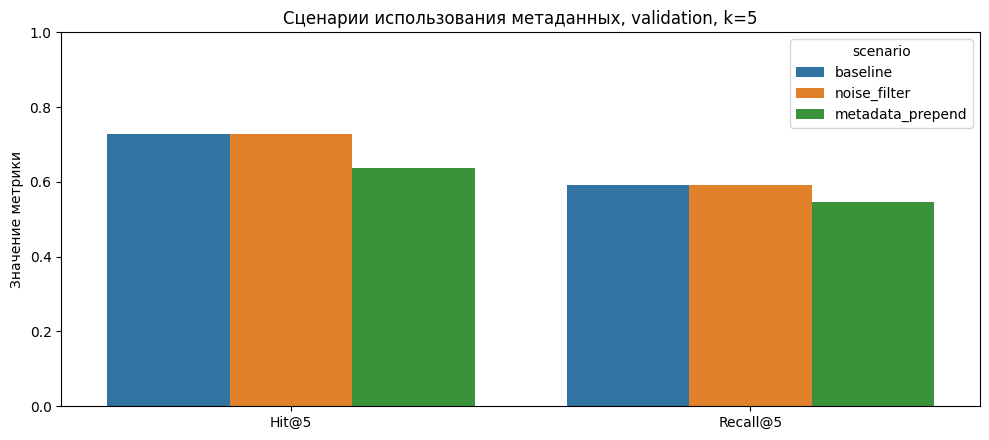

In [ ]:
metadata_plot_rows = []
for scenario, frame in [
    ("baseline", metadata_baseline_metrics),
    ("noise_filter", metadata_filter_metrics),
    ("metadata_prepend", metadata_prepend_metrics),
]:
    row = frame[frame["k"] == PRIMARY_K].iloc[0]
    for metric in ("Hit@k", "Recall@k"):
        metadata_plot_rows.append({
            "scenario": scenario,
            "metric": metric.replace("@k", f"@{PRIMARY_K}"),
            "value": row[metric],
        })
plt.figure(figsize=(10, 4.5))
sns.barplot(data=pd.DataFrame(metadata_plot_rows), x="metric", y="value", hue="scenario")
plt.ylim(0, 1)
plt.title(f"Сценарии использования метаданных, validation, k={PRIMARY_K}")
plt.xlabel("")
plt.ylabel("Значение метрики")
plt.tight_layout()
plt.savefig(OUT / "metadata_scenarios_validation.png", dpi=160, bbox_inches="tight")
plt.show()


Проверяются два независимых способа изменить индексное представление чанка:

Summary: BGE-M3 индексирует только резюме, но при попадании retriever возвращает исходный чанк. Гипотеза: факты могут потеряться при сжатии, а абстрактные темы — стать заметнее.
Hypothetical questions: для каждого чанка генерируются 2–3 вопроса, на которые он отвечает; BGE-M3 индексирует вопросы вместо исходного текста.

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer

CHUNK_LLM_MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
CHUNK_LLM_PROMPT_VERSION = "v1_ru_summary_questions"
CHUNK_LLM_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CHUNK_LLM_BATCH_SIZE = 32 if CHUNK_LLM_DEVICE == "cuda" else 1
CHUNK_LLM_MAX_INPUT_TOKENS = 1400
SUMMARY_MAX_NEW_TOKENS = 128
QUESTIONS_MAX_NEW_TOKENS = 128
LLM_DEBUG_MAX_CHUNKS = None  # например 50 для smoke-test; перед отчётом вернуть None

if CHUNK_LLM_DEVICE != "cuda":
    print("ВНИМАНИЕ: локальная LLM работает на CPU. Включите T4 GPU в настройках Colab.")
else:
    print("LLM-обработка на", torch.cuda.get_device_name(0))

torch.cuda.empty_cache() if torch.cuda.is_available() else None

if "chunk_llm_tokenizer" not in globals():
    chunk_llm_tokenizer = AutoTokenizer.from_pretrained(CHUNK_LLM_MODEL)
    chunk_llm_tokenizer.padding_side = "left"
    chunk_llm_tokenizer.truncation_side = "right"
    if chunk_llm_tokenizer.pad_token_id is None:
        chunk_llm_tokenizer.pad_token_id = chunk_llm_tokenizer.eos_token_id

if "chunk_llm" not in globals():
    model_dtype = torch.float16 if CHUNK_LLM_DEVICE == "cuda" else torch.float32
    chunk_llm = AutoModelForCausalLM.from_pretrained(
        CHUNK_LLM_MODEL, torch_dtype=model_dtype, low_cpu_mem_usage=True,
    ).to(CHUNK_LLM_DEVICE)
    chunk_llm.eval()


def summary_prompt(chunk):
    return (
        "Составь краткое информативное резюме фрагмента на русском языке. "
        "Сохрани имена собственные, географические названия, числа, даты и другие "
        "факты, которые могут понадобиться для ответа на вопрос. Не добавляй знания "
        "извне. Напиши 2–4 предложения и верни только резюме без предисловия.\n\n"
        f"Заголовок: {chunk['title']}\nФрагмент:\n{chunk['text']}"
    )


def questions_prompt(chunk):
    return (
        "Сгенерируй ровно 3 самостоятельных вопроса на русском языке, на которые "
        "можно ответить только по данному фрагменту. Включи конкретный фактический "
        "вопрос, более общий тематический вопрос и ещё один полезный поисковый вопрос. "
        "Не пиши ответы. Каждый вопрос выведи с новой строки, без пояснений.\n\n"
        f"Заголовок: {chunk['title']}\nФрагмент:\n{chunk['text']}"
    )


def apply_qwen_chat_template(prompts):
    return [
        chunk_llm_tokenizer.apply_chat_template(
            [
                {"role": "system", "content": "Ты аккуратный помощник по подготовке данных для RAG."},
                {"role": "user", "content": prompt},
            ],
            tokenize=False, add_generation_prompt=True,
        )
        for prompt in prompts
    ]


def generate_llm_batch(prompts, max_new_tokens):
    started = time.perf_counter()
    formatted = apply_qwen_chat_template(prompts)
    encoded = chunk_llm_tokenizer(
        formatted, padding=True, truncation=True,
        max_length=CHUNK_LLM_MAX_INPUT_TOKENS, return_tensors="pt",
    )
    input_token_counts = encoded["attention_mask"].sum(dim=1).tolist()
    encoded = {key: value.to(CHUNK_LLM_DEVICE) for key, value in encoded.items()}
    prompt_width = encoded["input_ids"].shape[1]
    with torch.inference_mode():
        output_ids = chunk_llm.generate(
            **encoded, max_new_tokens=max_new_tokens, do_sample=False,
            use_cache=True, pad_token_id=chunk_llm_tokenizer.pad_token_id,
            eos_token_id=chunk_llm_tokenizer.eos_token_id,
        )
    generated_ids = output_ids[:, prompt_width:]
    texts = [x.strip() for x in chunk_llm_tokenizer.batch_decode(
        generated_ids, skip_special_tokens=True
    )]
    output_token_counts = [
        len(chunk_llm_tokenizer.encode(text, add_special_tokens=False)) for text in texts
    ]
    elapsed = time.perf_counter() - started
    return texts, [int(x) for x in input_token_counts], output_token_counts, elapsed


def parse_generated_questions(text):
    candidates = []
    for line in text.splitlines():
        line = re.sub(r"^\s*(?:[-*•]+|\d+[.)]|[а-яА-Я][.)])\s*", "", line).strip()
        if not line:
            continue
        # Иногда маленькая модель выводит несколько вопросов одной строкой.
        pieces = re.split(r"(?<=\?)\s+", line)
        for piece in pieces:
            piece = piece.strip(" -•\t")
            if len(piece) >= 8:
                if not piece.endswith("?"):
                    piece += "?"
                if piece not in candidates:
                    candidates.append(piece)
    return candidates[:3]


def load_llm_checkpoint(path):
    records = {}
    if not path.exists():
        return records
    for line_number, line in enumerate(path.read_text(encoding="utf-8").splitlines(), 1):
        if not line.strip():
            continue
        try:
            row = json.loads(line)
        except json.JSONDecodeError:
            print(f"Пропущена повреждённая строка checkpoint: {line_number}")
            continue
        if (
            row.get("model") == CHUNK_LLM_MODEL
            and row.get("prompt_version") == CHUNK_LLM_PROMPT_VERSION
        ):
            records[row["chunk_id"]] = row
    return records


def append_llm_checkpoint(path, rows):
    # Если Colab был остановлен посреди записи, начинаем новую строку.
    if path.exists() and path.stat().st_size:
        with path.open("rb+") as f:
            f.seek(-1, os.SEEK_END)
            if f.read(1) != b"\n":
                f.seek(0, os.SEEK_END)
                f.write(b"\n")
    with path.open("a", encoding="utf-8") as f:
        for row in rows:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")
        f.flush()


def generate_chunk_artifacts(chunks, checkpoint_path, batch_size=CHUNK_LLM_BATCH_SIZE):
    cached = load_llm_checkpoint(checkpoint_path)
    missing = [chunk for chunk in chunks if chunk["chunk_id"] not in cached]
    print(f"LLM checkpoint: готово {len(chunks) - len(missing)}/{len(chunks)}, осталось {len(missing)}")

    for start in range(0, len(missing), batch_size):
        batch = missing[start:start + batch_size]

        summaries, s_in, s_out, s_seconds = generate_llm_batch(
            [summary_prompt(x) for x in batch], SUMMARY_MAX_NEW_TOKENS
        )
        raw_questions, q_in, q_out, q_seconds = generate_llm_batch(
            [questions_prompt(x) for x in batch], QUESTIONS_MAX_NEW_TOKENS
        )
        parsed_questions = [parse_generated_questions(text) for text in raw_questions]

        # Один детерминированный retry только для ответов, где получилось <2 вопросов.
        bad = [i for i, questions in enumerate(parsed_questions) if len(questions) < 2]
        retry_tokens_in = {i: 0 for i in range(len(batch))}
        retry_tokens_out = {i: 0 for i in range(len(batch))}
        retry_seconds_per_item = {i: 0.0 for i in range(len(batch))}
        if bad:
            retry_prompts = [
                questions_prompt(batch[i])
                + "\n\nКРИТИЧНО: верни три разные строки, каждая должна заканчиваться знаком вопроса."
                for i in bad
            ]
            retry_texts, r_in, r_out, r_seconds = generate_llm_batch(
                retry_prompts, QUESTIONS_MAX_NEW_TOKENS
            )
            for local_i, batch_i in enumerate(bad):
                retry_questions = parse_generated_questions(retry_texts[local_i])
                if len(retry_questions) >= len(parsed_questions[batch_i]):
                    parsed_questions[batch_i] = retry_questions
                    raw_questions[batch_i] = retry_texts[local_i]
                retry_tokens_in[batch_i] = r_in[local_i]
                retry_tokens_out[batch_i] = r_out[local_i]
                retry_seconds_per_item[batch_i] = r_seconds / len(bad)

        new_rows = []
        for i, chunk in enumerate(batch):
            row = {
                "chunk_id": chunk["chunk_id"],
                "model": CHUNK_LLM_MODEL,
                "prompt_version": CHUNK_LLM_PROMPT_VERSION,
                "summary": summaries[i],
                "questions": parsed_questions[i],
                "raw_questions_output": raw_questions[i],
                "summary_input_tokens": s_in[i],
                "summary_output_tokens": s_out[i],
                "questions_input_tokens": q_in[i] + retry_tokens_in[i],
                "questions_output_tokens": q_out[i] + retry_tokens_out[i],
                "summary_seconds": s_seconds / len(batch),
                "questions_seconds": q_seconds / len(batch) + retry_seconds_per_item[i],
                "summary_valid": bool(summaries[i].strip()),
                "questions_valid": 2 <= len(parsed_questions[i]) <= 3,
            }
            cached[chunk["chunk_id"]] = row
            new_rows.append(row)
        append_llm_checkpoint(checkpoint_path, new_rows)
        done = min(start + len(batch), len(missing))
        print(f"  сгенерировано в этом запуске: {done}/{len(missing)}")

    return [cached[chunk["chunk_id"]] for chunk in chunks]


LLM_EVAL_CHUNKS = (
    METADATA_CHUNKS if LLM_DEBUG_MAX_CHUNKS is None
    else METADATA_CHUNKS[:LLM_DEBUG_MAX_CHUNKS]
)
if LLM_DEBUG_MAX_CHUNKS is not None:
    print("ВНИМАНИЕ: это debug-индекс; его метрики нельзя использовать в отчёте.")

LLM_CHECKPOINT = OUT / "llm_chunk_artifacts_qwen25_05b.jsonl"
LLM_ARTIFACTS = generate_chunk_artifacts(LLM_EVAL_CHUNKS, LLM_CHECKPOINT)
LLM_ARTIFACT_BY_ID = {row["chunk_id"]: row for row in LLM_ARTIFACTS}

invalid_summaries = sum(not x["summary_valid"] for x in LLM_ARTIFACTS)
invalid_questions = sum(not x["questions_valid"] for x in LLM_ARTIFACTS)
print("Пустых summary:", invalid_summaries)
print("Чанков не с 2–3 вопросами после retry:", invalid_questions)

if invalid_summaries:
    raise ValueError("Есть пустые summary. Проверьте LLM checkpoint перед оценкой.")
if invalid_questions:
    raise ValueError(
        "Не для всех чанков получено 2–3 вопроса. Исправьте отмеченные записи checkpoint."
    )

review_ids = sorted(
    [x["chunk_id"] for x in LLM_EVAL_CHUNKS],
    key=lambda value: sha256_text(f"{SEED}|{value}"),
)[:5]
display(pd.DataFrame([
    {
        "title": chunk["title"],
        "original_excerpt": chunk["text"][:350],
        "summary": LLM_ARTIFACT_BY_ID[chunk["chunk_id"]]["summary"],
        "questions": LLM_ARTIFACT_BY_ID[chunk["chunk_id"]]["questions"],
    }
    for chunk in LLM_EVAL_CHUNKS if chunk["chunk_id"] in set(review_ids)
]))


LLM-обработка на Tesla T4
LLM checkpoint: готово 448/10965, осталось 10517
  сгенерировано в этом запуске: 32/10517
  сгенерировано в этом запуске: 64/10517
  сгенерировано в этом запуске: 96/10517
  сгенерировано в этом запуске: 128/10517
  сгенерировано в этом запуске: 160/10517
  сгенерировано в этом запуске: 192/10517
  сгенерировано в этом запуске: 224/10517
  сгенерировано в этом запуске: 256/10517
  сгенерировано в этом запуске: 288/10517
  сгенерировано в этом запуске: 320/10517
  сгенерировано в этом запуске: 352/10517
  сгенерировано в этом запуске: 384/10517
  сгенерировано в этом запуске: 416/10517
  сгенерировано в этом запуске: 448/10517
  сгенерировано в этом запуске: 480/10517
  сгенерировано в этом запуске: 512/10517
  сгенерировано в этом запуске: 544/10517
  сгенерировано в этом запуске: 576/10517
  сгенерировано в этом запуске: 608/10517
  сгенерировано в этом запуске: 640/10517
  сгенерировано в этом запуске: 672/10517
  сгенерировано в этом запуске: 704/10517
  сг

ValueError: Не для всех чанков получено 2–3 вопроса. Исправьте отмеченные записи checkpoint.

 Индексация summary и гипотетических вопросов

In [ ]:
SUMMARY_INDEX_ITEMS = []
HYDE_INDEX_ITEMS = []
for chunk in LLM_EVAL_CHUNKS:
    artifact = LLM_ARTIFACT_BY_ID[chunk["chunk_id"]]
    summary = artifact["summary"].strip()
    questions_text = "\n".join(artifact["questions"])
    SUMMARY_INDEX_ITEMS.append({
        **chunk,
        "chunk_id": f"{chunk['chunk_id']}_summary_{sha256_text(summary)[:8]}",
        "text": summary,
    })
    HYDE_INDEX_ITEMS.append({
        **chunk,
        "chunk_id": f"{chunk['chunk_id']}_hyde_{sha256_text(questions_text)[:8]}",
        "text": questions_text,
        "hypothetical_questions": artifact["questions"],
    })

summary_vectors, summary_embedding_seconds, summary_embeddings_cached = encode_bge_items(
    SUMMARY_INDEX_ITEMS, "bge_llm_summary"
)
hyde_vectors, hyde_embedding_seconds, hyde_embeddings_cached = encode_bge_items(
    HYDE_INDEX_ITEMS, "bge_llm_hypothetical_questions"
)
SUMMARY_RETRIEVER = DenseChunkRetriever(summary_vectors)
HYDE_RETRIEVER = DenseChunkRetriever(hyde_vectors)

(
    summary_metrics, summary_by_type, summary_queries,
    summary_alignment, summary_negative,
) = evaluate_dense_retriever(
    SUMMARY_RETRIEVER, LLM_EVAL_CHUNKS, validation_gold, BGE_QUERY_VECTORS,
    quote_transform=STAGE_QUOTE_TRANSFORMS[FINAL_STAGE], aliases=duplicate_aliases,
)
(
    hyde_metrics, hyde_by_type, hyde_queries,
    hyde_alignment, hyde_negative,
) = evaluate_dense_retriever(
    HYDE_RETRIEVER, LLM_EVAL_CHUNKS, validation_gold, BGE_QUERY_VECTORS,
    quote_transform=STAGE_QUOTE_TRANSFORMS[FINAL_STAGE], aliases=duplicate_aliases,
)

# Baseline пересчитывается на том же наборе чанков. При полном запуске он
# совпадает с metadata_baseline_metrics; при debug честно использует subset.
llm_baseline_vectors = simple_vectors[:len(LLM_EVAL_CHUNKS)]
LLM_BASELINE_RETRIEVER = DenseChunkRetriever(llm_baseline_vectors)
(
    llm_baseline_metrics, llm_baseline_by_type, llm_baseline_queries,
    llm_baseline_alignment, llm_baseline_negative,
) = evaluate_dense_retriever(
    LLM_BASELINE_RETRIEVER, LLM_EVAL_CHUNKS, validation_gold, BGE_QUERY_VECTORS,
    quote_transform=STAGE_QUOTE_TRANSFORMS[FINAL_STAGE], aliases=duplicate_aliases,
)

llm_metrics_all = []
llm_metrics_by_type_all = []
for approach, metrics, by_type in [
    ("original_text", llm_baseline_metrics, llm_baseline_by_type),
    ("summary", summary_metrics, summary_by_type),
    ("hypothetical_questions", hyde_metrics, hyde_by_type),
]:
    temp = metrics.copy()
    temp.insert(0, "approach", approach)
    llm_metrics_all.append(temp)
    temp_type = by_type.copy()
    temp_type.insert(0, "approach", approach)
    llm_metrics_by_type_all.append(temp_type)

llm_chunk_metrics = pd.concat(llm_metrics_all, ignore_index=True)
llm_chunk_metrics_by_type = pd.concat(llm_metrics_by_type_all, ignore_index=True)
llm_chunk_metrics.to_csv(OUT / "llm_chunk_retrieval_metrics_validation.csv", index=False)
llm_chunk_metrics_by_type.to_csv(
    OUT / "llm_chunk_metrics_by_type_validation.csv", index=False
)

display(llm_chunk_metrics.style.format({
     "Hit@k": "{:.3f}", "Recall@k": "{:.3f}",
    "aligned_evidence_share": "{:.2%}", "mean_best_evidence_coverage": "{:.3f}",
}))


,approach,k,positive_questions,Hit@k,Recall@k,aligned_evidence_share,mean_best_evidence_coverage
0,original_text,1,11,0.545,0.409,94.12%,0.929
1,original_text,3,11,0.636,0.545,94.12%,0.929
2,original_text,5,11,0.727,0.591,94.12%,0.929
3,original_text,10,11,0.727,0.636,94.12%,0.929
4,summary,1,11,0.455,0.318,94.12%,0.929
5,summary,3,11,0.545,0.500,94.12%,0.929
6,summary,5,11,0.636,0.545,94.12%,0.929
7,summary,10,11,0.727,0.591,94.12%,0.929
8,hypothetical_questions,1,11,0.455,0.409,94.12%,0.929
9,hypothetical_questions,3,11,0.545,0.500,94.12%,0.929


Стоимость: токены, время и размер индекса

In [ ]:
def processing_cost_row(approach, artifacts, input_field, output_field, seconds_field, index_items):
    input_tokens = int(sum(x[input_field] for x in artifacts))
    output_tokens = int(sum(x[output_field] for x in artifacts))
    seconds = float(sum(x[seconds_field] for x in artifacts))
    return {
        "approach": approach,
        "model": CHUNK_LLM_MODEL,
        "prompt_version": CHUNK_LLM_PROMPT_VERSION,
        "temperature": 0.0,
        "batch_size": CHUNK_LLM_BATCH_SIZE,
        "max_input_tokens": CHUNK_LLM_MAX_INPUT_TOKENS,
        "chunks": len(artifacts),
        "input_tokens": input_tokens,
        "output_tokens": output_tokens,
        "total_llm_tokens": input_tokens + output_tokens,
        "generation_seconds": seconds,
        "seconds_per_chunk": seconds / max(1, len(artifacts)),
        "output_tokens_per_second": output_tokens / max(seconds, 1e-9),
        "indexed_text_tokens_gpt2": sum(count_model_tokens(x["text"]) for x in index_items),
        "local_api_cost_usd": 0.0,
    }


llm_processing_costs = pd.DataFrame([
    processing_cost_row(
        "summary", LLM_ARTIFACTS,
        "summary_input_tokens", "summary_output_tokens", "summary_seconds",
        SUMMARY_INDEX_ITEMS,
    ),
    processing_cost_row(
        "hypothetical_questions", LLM_ARTIFACTS,
        "questions_input_tokens", "questions_output_tokens", "questions_seconds",
        HYDE_INDEX_ITEMS,
    ),
])
llm_processing_costs["bge_embedding_seconds_this_run"] = [
    summary_embedding_seconds, hyde_embedding_seconds
]
llm_processing_costs.to_csv(OUT / "llm_chunk_processing_costs.csv", index=False)
display(llm_processing_costs.style.format({
    "generation_seconds": "{:.1f}", "seconds_per_chunk": "{:.3f}",
    "output_tokens_per_second": "{:.1f}",
    "bge_embedding_seconds_this_run": "{:.1f}", "local_api_cost_usd": "${:.2f}",
}))


,approach,model,prompt_version,temperature,batch_size,max_input_tokens,chunks,input_tokens,output_tokens,total_llm_tokens,generation_seconds,seconds_per_chunk,output_tokens_per_second,indexed_text_tokens_gpt2,local_api_cost_usd,bge_embedding_seconds_this_run
0,summary,Qwen/Qwen2.5-0.5B-Instruct,v1_ru_summary_questions,0.000000,32,1400,10965,4537826,1382840,5920666,2234.3,0.204,618.9,2986147,$0.00,290.1
1,hypothetical_questions,Qwen/Qwen2.5-0.5B-Instruct,v1_ru_summary_questions,0.000000,32,1400,10965,4453195,1093584,5546779,2508.1,0.229,436.0,2354340,$0.00,191.8


Проверка гипотезы по типам и итог «качество против затрат»

In [ ]:
baseline_type_k = llm_baseline_by_type[
    llm_baseline_by_type["k"] == PRIMARY_K
][["question_type", "n_questions", "Hit@k", "Recall@k"]].copy()
baseline_type_k = baseline_type_k.rename(columns={
    "Hit@k": "baseline_hit",
    "Recall@k": "baseline_recall",
})

llm_type_comparison_rows = []
for approach, frame in [("summary", summary_by_type), ("hypothetical_questions", hyde_by_type)]:
    current = frame[frame["k"] == PRIMARY_K].merge(
        baseline_type_k, on=["question_type", "n_questions"], how="left"
    )
    for _, row in current.iterrows():
        llm_type_comparison_rows.append({
            "approach": approach,
            "question_type": row["question_type"],
            "n_questions": int(row["n_questions"]),
            "baseline_hit": row["baseline_hit"],
            "approach_hit": row["Hit@k"],
            "delta_hit": row["Hit@k"] - row["baseline_hit"],
            "baseline_recall": row["baseline_recall"],
            "approach_recall": row["Recall@k"],
            "delta_recall": row["Recall@k"] - row["baseline_recall"],
        })

llm_chunk_comparison_by_type = pd.DataFrame(llm_type_comparison_rows)
llm_chunk_comparison_by_type.to_csv(
    OUT / "llm_chunk_comparison_by_type_validation.csv", index=False
)
display(llm_chunk_comparison_by_type.style.format({
    "approach_hit": "{:.3f}", "delta_hit": "{:+.3f}",
    "baseline_recall": "{:.3f}", "approach_recall": "{:.3f}",
    "delta_recall": "{:+.3f}",
}).background_gradient(subset=["delta_recall"], cmap="RdYlGn", vmin=-0.3, vmax=0.3))

baseline_primary = llm_baseline_metrics[llm_baseline_metrics["k"] == PRIMARY_K].iloc[0]
llm_overall_rows = []
for approach, frame in [("summary", summary_metrics), ("hypothetical_questions", hyde_metrics)]:
    row = frame[frame["k"] == PRIMARY_K].iloc[0]
    llm_overall_rows.append({
        "approach": approach,
        "Hit@k": row["Hit@k"],
        "Recall@k": row["Recall@k"],
        "delta_hit": row["Hit@k"] - baseline_primary["Hit@k"],
        "delta_recall": row["Recall@k"] - baseline_primary["Recall@k"],
    })
llm_overall_comparison = pd.DataFrame(llm_overall_rows).merge(
    llm_processing_costs, on="approach", how="left"
)
llm_overall_comparison["delta_recall_per_million_tokens"] = (
    llm_overall_comparison["delta_recall"]
    / llm_overall_comparison["total_llm_tokens"].clip(lower=1)
    * 1_000_000
)
llm_overall_comparison.to_csv(
    OUT / "llm_chunk_quality_vs_cost_validation.csv", index=False
)
display(llm_overall_comparison.style.format({
    "delta_recall": "{:+.3f}", "generation_seconds": "{:.1f}",
    "delta_recall_per_million_tokens": "{:+.4f}",
}))

summary_type_result = llm_chunk_comparison_by_type[
    llm_chunk_comparison_by_type["approach"] == "summary"
].set_index("question_type")
factual_delta = summary_type_result.loc["factual", "delta_recall"] if "factual" in summary_type_result.index else math.nan
abstract_delta = summary_type_result.loc["abstract", "delta_recall"] if "abstract" in summary_type_result.index else math.nan
if factual_delta < 0 and abstract_delta > 0:
    hypothesis_verdict = "подтвердилась"
elif factual_delta < 0 or abstract_delta > 0:
    hypothesis_verdict = "подтвердилась частично"
else:
    hypothesis_verdict = "не подтвердилась"
print(
    f"Гипотеза summary (factual хуже, abstract лучше) {hypothesis_verdict}: "
    f"ΔRecall@{PRIMARY_K} factual={factual_delta:+.3f}, abstract={abstract_delta:+.3f}."
)

for _, row in llm_overall_comparison.iterrows():
    if row["delta_recall"] > 0 and row["delta_hit"] >= 0:
        verdict = (
            "прирост потенциально оправдывает затраты на validation; "
            "окончательное решение — только после единственного test-запуска"
        )
    elif row["delta_recall"] <= 0 and row["delta_hit"] <= 0:
        verdict = "затраты не оправданы: качество не выросло"
    else:
        verdict = "компромисс неоднозначен: одна метрика выросла, другая снизилась"
    print(
        f"- {row['approach']}: {verdict}. "
        f"LLM tokens={int(row['total_llm_tokens']):,}, "
        f"время={row['generation_seconds']:.1f} с, ΔRecall@{PRIMARY_K}={row['delta_recall']:+.3f}."
    )


,approach,question_type,n_questions,baseline_hit,approach_hit,delta_hit,baseline_recall,approach_recall,delta_recall
0,summary,abstract,3,0.666667,0.667,+0.000,0.333,0.500,+0.167
1,summary,composite,3,0.666667,0.667,+0.000,0.500,0.500,+0.000
2,summary,factual,5,0.800000,0.600,-0.200,0.800,0.600,-0.200
3,hypothetical_questions,abstract,3,0.666667,0.667,+0.000,0.333,0.500,+0.167
4,hypothetical_questions,composite,3,0.666667,0.333,-0.333,0.500,0.167,-0.333
5,hypothetical_questions,factual,5,0.800000,0.800,+0.000,0.800,0.800,+0.000


,approach,Hit@k,Recall@k,delta_hit,delta_recall,model,prompt_version,temperature,batch_size,max_input_tokens,chunks,input_tokens,output_tokens,total_llm_tokens,generation_seconds,seconds_per_chunk,output_tokens_per_second,indexed_text_tokens_gpt2,local_api_cost_usd,bge_embedding_seconds_this_run,delta_recall_per_million_tokens
0,summary,0.636364,0.545455,-0.090909,-0.045,Qwen/Qwen2.5-0.5B-Instruct,v1_ru_summary_questions,0.000000,32,1400,10965,4537826,1382840,5920666,2234.3,0.203767,618.912472,2986147,0.000000,290.146653,-0.0077
1,hypothetical_questions,0.636364,0.545455,-0.090909,-0.045,Qwen/Qwen2.5-0.5B-Instruct,v1_ru_summary_questions,0.000000,32,1400,10965,4453195,1093584,5546779,2508.1,0.228732,436.029310,2354340,0.000000,191.818721,-0.0082


Гипотеза summary (factual хуже, abstract лучше) подтвердилась: ΔRecall@5 factual=-0.200, abstract=+0.167.
- summary: затраты не оправданы: качество не выросло. LLM tokens=5,920,666, время=2234.3 с, ΔRecall@5=-0.045.
- hypothetical_questions: затраты не оправданы: качество не выросло. LLM tokens=5,546,779, время=2508.1 с, ΔRecall@5=-0.045.


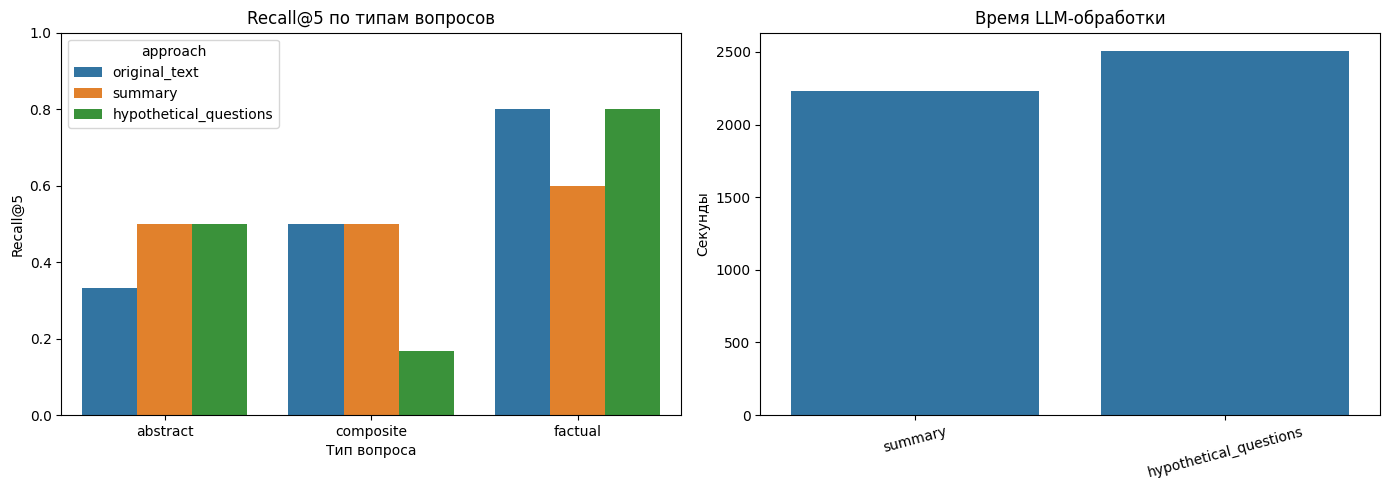

In [ ]:
llm_plot = llm_chunk_metrics_by_type[
    llm_chunk_metrics_by_type["k"] == PRIMARY_K
].copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(
    data=llm_plot, x="question_type", y="Recall@k", hue="approach", ax=axes[0]
)
axes[0].set_ylim(0, 1)
axes[0].set_title(f"Recall@{PRIMARY_K} по типам вопросов")
axes[0].set_xlabel("Тип вопроса")
axes[0].set_ylabel(f"Recall@{PRIMARY_K}")
sns.barplot(
    data=llm_processing_costs, x="approach", y="generation_seconds", ax=axes[1]
)
axes[1].set_title("Время LLM-обработки")
axes[1].set_xlabel("")
axes[1].set_ylabel("Секунды")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(OUT / "llm_chunk_quality_and_cost.png", dpi=160, bbox_inches="tight")
plt.show()

# Освобождаем память перед последующими BGE/test-операциями. Checkpoint уже сохранён.
if "chunk_llm" in globals():
    del chunk_llm
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Итоговая сравнительная таблица

In [ ]:
def comparison_metric_columns(metrics, split_prefix="validation"):
    result = {}
    for k in KS:
        part = metrics[metrics["k"] == k]
        if part.empty:
            continue
        row = part.iloc[0]
        for metric in ("Precision@k", "Hit@k", "Recall@k"):
            if metric in row.index:
                name = metric.replace("@k", f"@{k}")
                result[f"{split_prefix}_{name}"] = row[metric]
    primary = metrics[metrics["k"] == PRIMARY_K]
    if not primary.empty:
        row = primary.iloc[0]
        for source, target in [
            ("aligned_evidence_share", "aligned_evidence_share"),
            ("mean_best_evidence_coverage", "mean_best_evidence_coverage"),
        ]:
            if source in row.index:
                result[f"{split_prefix}_{target}"] = row[source]
    return result


def mean_context_tokens(chunks):
    return float(np.mean([x["token_count"] for x in chunks])) if chunks else math.nan


def mean_generated_index_tokens(items):
    return float(np.mean([count_model_tokens(x["text"]) for x in items])) if items else math.nan


def make_comparison_row(
    *, configuration_key, experiment_family, preprocessing, chunker,
    chunker_parameters, retriever, metadata_mode, llm_processing,
    context_chunks, index_items, metrics, chunking_seconds=0.0,
    metadata_processing_seconds=0.0, llm_processing_seconds=0.0,
    indexing_seconds=0.0, index_text_is_original=True, notes="",
):
    mean_index_tokens = (
        mean_context_tokens(index_items)
        if index_text_is_original
        else mean_generated_index_tokens(index_items)
    )
    row = {
        "configuration_key": configuration_key,
        "experiment_family": experiment_family,
        "preprocessing": preprocessing,
        "chunker": chunker,
        "chunker_parameters": chunker_parameters,
        "retriever": retriever,
        "metadata_mode": metadata_mode,
        "llm_processing": llm_processing,
        "context_items": len(context_chunks),
        "index_items": len(index_items),
        "mean_chunk_tokens": mean_context_tokens(context_chunks),
        "mean_index_text_tokens": mean_index_tokens,
        "chunking_seconds": float(chunking_seconds),
        "metadata_processing_seconds": float(metadata_processing_seconds),
        "llm_processing_seconds": float(llm_processing_seconds),
        "indexing_seconds": float(indexing_seconds),
        "total_preparation_seconds": float(
            chunking_seconds + metadata_processing_seconds
            + llm_processing_seconds + indexing_seconds
        ),
        "notes": notes,
    }
    row.update(comparison_metric_columns(metrics, "validation"))
    return row


comparison_rows = []

# 1. Последовательные стадии предобработки при фиксированном TokenChunker+TF-IDF.
for _, result in preprocessing_results.iterrows():
    stage = result["stage"]
    chunks = token_chunks_by_stage[stage]
    metrics = preprocessing_metrics_long[preprocessing_metrics_long["stage"] == stage]
    comparison_rows.append(make_comparison_row(
        configuration_key=f"chunker|{stage}|TokenChunker",
        experiment_family="preprocessing",
        preprocessing=stage,
        chunker="TokenChunker",
        chunker_parameters=json.dumps(
            {"chunk_size": CHUNK_SIZE, "overlap": CHUNK_OVERLAP}, ensure_ascii=False
        ),
        retriever="word_TF-IDF_(1,2)-grams",
        metadata_mode="none",
        llm_processing="none",
        context_chunks=chunks,
        index_items=chunks,
        metrics=metrics,
        chunking_seconds=result["chunking_seconds"],
    ))

# 2. Основные стратегии Chonkie на финальном корпусе.
for _, result in chunking_results.iterrows():
    chunker_name = result["chunker"]
    chunks = chunks_by_chunker[chunker_name]
    metrics = chunking_metrics_all_k[chunking_metrics_all_k["chunker"] == chunker_name]
    comparison_rows.append(make_comparison_row(
        configuration_key=f"chunker|{FINAL_STAGE}|{chunker_name}",
        experiment_family="chunker_comparison",
        preprocessing=FINAL_STAGE,
        chunker=chunker_name,
        chunker_parameters=json.dumps({"target_size": CHUNK_SIZE}, ensure_ascii=False),
        retriever="word_TF-IDF_(1,2)-grams",
        metadata_mode="none",
        llm_processing="none",
        context_chunks=chunks,
        index_items=chunks,
        metrics=metrics,
        chunking_seconds=result["chunking_seconds"],
    ))

# 3. Все thresholds SemanticChunker.
for _, result in threshold_ablation.iterrows():
    model_name = result["embedder"]
    threshold = float(result["threshold"])
    chunks = SEMANTIC_ABLATION_CHUNKS[(model_name, threshold)]
    metrics = threshold_metrics_all_k[
        (threshold_metrics_all_k["embedder"] == model_name)
        & np.isclose(threshold_metrics_all_k["threshold"], threshold)
    ]
    comparison_rows.append(make_comparison_row(
        configuration_key=f"semantic|{model_name}|{threshold:.6f}",
        experiment_family="semantic_threshold_ablation",
        preprocessing=ABLATION_STAGE,
        chunker="SemanticChunker",
        chunker_parameters=json.dumps(
            {"cosine_threshold": threshold, "embedding_model": model_name},
            ensure_ascii=False,
        ),
        retriever="word_TF-IDF_(1,2)-grams",
        metadata_mode="none",
        llm_processing="none",
        context_chunks=chunks,
        index_items=chunks,
        metrics=metrics,
        chunking_seconds=result["chunking_seconds"],
    ))

# 4. Ablation модели границ при выбранном threshold.
for _, result in embedder_ablation.iterrows():
    model_name = result["embedder"]
    threshold = float(result["threshold"])
    chunks = SEMANTIC_ABLATION_CHUNKS[(model_name, threshold)]
    metrics = embedder_metrics_all_k[
        (embedder_metrics_all_k["embedder"] == model_name)
        & np.isclose(embedder_metrics_all_k["threshold"], threshold)
    ]
    comparison_rows.append(make_comparison_row(
        configuration_key=f"semantic|{model_name}|{threshold:.6f}",
        experiment_family="semantic_embedder_ablation",
        preprocessing=ABLATION_STAGE,
        chunker="SemanticChunker",
        chunker_parameters=json.dumps(
            {"cosine_threshold": threshold, "embedding_model": model_name},
            ensure_ascii=False,
        ),
        retriever="word_TF-IDF_(1,2)-grams",
        metadata_mode="none",
        llm_processing="none",
        context_chunks=chunks,
        index_items=chunks,
        metrics=metrics,
        chunking_seconds=result["chunking_seconds"],
    ))

best_simple_info = chunking_results[
    chunking_results["chunker"] == BEST_SIMPLE_CHUNKER
].iloc[0]

# 5. Общий BGE-M3 baseline для сложных экспериментов.
comparison_rows.append(make_comparison_row(
    configuration_key=f"bge_simple|{BEST_SIMPLE_CHUNKER}",
    experiment_family="dense_baseline",
    preprocessing=FINAL_STAGE,
    chunker=BEST_SIMPLE_CHUNKER,
    chunker_parameters=json.dumps({"target_size": CHUNK_SIZE}, ensure_ascii=False),
    retriever="BAAI/bge-m3_dense_bruteforce",
    metadata_mode="none",
    llm_processing="none",
    context_chunks=BEST_SIMPLE_CHUNKS,
    index_items=BEST_SIMPLE_CHUNKS,
    metrics=bge_simple_metrics,
    chunking_seconds=best_simple_info["chunking_seconds"],
    indexing_seconds=simple_embedding_seconds,
    notes="Общий dense baseline для parent/metadata/LLM экспериментов.",
))

# 6. ParentDocumentRetriever: индексируются children, возвращаются parents.
for _, result in parent_document_results.iterrows():
    config_name = result["config"]
    run = PARENT_RUNS[config_name]
    comparison_rows.append(make_comparison_row(
        configuration_key=f"parent|{config_name}",
        experiment_family="parent_document",
        preprocessing=FINAL_STAGE,
        chunker="ParentDocumentRetriever",
        chunker_parameters=json.dumps(run["config"], ensure_ascii=False),
        retriever="BAAI/bge-m3_child_max-score_to_parent",
        metadata_mode="parent_id_mapping",
        llm_processing="none",
        context_chunks=run["parents"],
        index_items=run["children"],
        metrics=run["metrics"],
        chunking_seconds=result["chunking_seconds"],
        indexing_seconds=result["embedding_seconds"],
        notes="mean_chunk_tokens=parent; mean_index_text_tokens=child.",
    ))

# 7. Два сценария использования метаданных.
comparison_rows.append(make_comparison_row(
    configuration_key="metadata|noise_filter",
    experiment_family="metadata",
    preprocessing=FINAL_STAGE,
    chunker=BEST_SIMPLE_CHUNKER,
    chunker_parameters=json.dumps({"target_size": CHUNK_SIZE}, ensure_ascii=False),
    retriever="BAAI/bge-m3_dense_bruteforce",
    metadata_mode=f"noise_score_filter_q{QUALITY_KEEP_QUANTILE:.2f}",
    llm_processing="none",
    context_chunks=QUALITY_FILTERED_CHUNKS,
    index_items=QUALITY_FILTERED_CHUNKS,
    metrics=metadata_filter_metrics,
    chunking_seconds=best_simple_info["chunking_seconds"],
    indexing_seconds=simple_embedding_seconds,
    notes="Фильтр применён к общей BGE-матрице; время отражает фактически построенную матрицу.",
))
comparison_rows.append(make_comparison_row(
    configuration_key="metadata|prepend",
    experiment_family="metadata",
    preprocessing=FINAL_STAGE,
    chunker=BEST_SIMPLE_CHUNKER,
    chunker_parameters=json.dumps({"target_size": CHUNK_SIZE}, ensure_ascii=False),
    retriever="BAAI/bge-m3_dense_bruteforce",
    metadata_mode="prepend_source_language_type_position_keywords",
    llm_processing="none",
    context_chunks=METADATA_CHUNKS,
    index_items=METADATA_PREPEND_ITEMS,
    metrics=metadata_prepend_metrics,
    chunking_seconds=best_simple_info["chunking_seconds"],
    indexing_seconds=metadata_prepend_seconds,
    index_text_is_original=False,
))

# 8. Два LLM-представления чанков.
summary_cost = llm_processing_costs[
    llm_processing_costs["approach"] == "summary"
].iloc[0]
questions_cost = llm_processing_costs[
    llm_processing_costs["approach"] == "hypothetical_questions"
].iloc[0]
comparison_rows.append(make_comparison_row(
    configuration_key="llm|summary",
    experiment_family="llm_processing",
    preprocessing=FINAL_STAGE,
    chunker=BEST_SIMPLE_CHUNKER,
    chunker_parameters=json.dumps({"target_size": CHUNK_SIZE}, ensure_ascii=False),
    retriever="BAAI/bge-m3_dense_bruteforce",
    metadata_mode="stored_not_indexed",
    llm_processing=f"summary:{CHUNK_LLM_MODEL}",
    context_chunks=LLM_EVAL_CHUNKS,
    index_items=SUMMARY_INDEX_ITEMS,
    metrics=summary_metrics,
    chunking_seconds=best_simple_info["chunking_seconds"],
    llm_processing_seconds=summary_cost["generation_seconds"],
    indexing_seconds=summary_embedding_seconds,
    index_text_is_original=False,
))
comparison_rows.append(make_comparison_row(
    configuration_key="llm|hypothetical_questions",
    experiment_family="llm_processing",
    preprocessing=FINAL_STAGE,
    chunker=BEST_SIMPLE_CHUNKER,
    chunker_parameters=json.dumps({"target_size": CHUNK_SIZE}, ensure_ascii=False),
    retriever="BAAI/bge-m3_dense_bruteforce",
    metadata_mode="stored_not_indexed",
    llm_processing=f"2-3_questions:{CHUNK_LLM_MODEL}",
    context_chunks=LLM_EVAL_CHUNKS,
    index_items=HYDE_INDEX_ITEMS,
    metrics=hyde_metrics,
    chunking_seconds=best_simple_info["chunking_seconds"],
    llm_processing_seconds=questions_cost["generation_seconds"],
    indexing_seconds=hyde_embedding_seconds,
    index_text_is_original=False,
))

final_comparison_table = pd.DataFrame(comparison_rows)
# Одинаковая конфигурация могла встретиться в основном сравнении и ablation.
final_comparison_table = final_comparison_table.drop_duplicates(
    subset=["configuration_key"], keep="last"
).reset_index(drop=True)

# Test-метрики существуют только у выбранной и зафиксированной конфигурации.
for k in KS:
    for metric in ("Precision", "Hit", "Recall"):
        final_comparison_table[f"test_{metric}@{k}"] = math.nan
final_comparison_table["test_aligned_evidence_share"] = math.nan
final_comparison_table["test_mean_best_evidence_coverage"] = math.nan

final_comparison_table["validation_rank_by_recall5"] = (
    final_comparison_table["validation_Recall@5"]
    .rank(method="min", ascending=False)
    .astype("Int64")
)
final_comparison_table = final_comparison_table.sort_values(
    ["validation_rank_by_recall5", "validation_Hit@5", "indexing_seconds"],
    ascending=[True, False, True], kind="stable",
).reset_index(drop=True)

final_comparison_table.to_csv(
    OUT / "final_configuration_comparison.csv", index=False
)
(OUT / "final_configuration_comparison.json").write_text(
    final_comparison_table.to_json(orient="records", force_ascii=False, indent=2),
    encoding="utf-8",
)

comparison_display_columns = [
    "validation_rank_by_recall5", "configuration_key", "preprocessing",
    "chunker", "metadata_mode", "llm_processing", "retriever",
    "mean_chunk_tokens", "mean_index_text_tokens", "indexing_seconds",
     "validation_Hit@5", "validation_Recall@5",
    "test_Precision@5", "test_Hit@5", "test_Recall@5",
]
display(final_comparison_table[comparison_display_columns].style.format({
    "mean_chunk_tokens": "{:.1f}", "mean_index_text_tokens": "{:.1f}",
    "indexing_seconds": "{:.1f}", "validation_Precision@5": "{:.3f}",
    "validation_Hit@5": "{:.3f}", "validation_Recall@5": "{:.3f}",
     "test_Hit@5": "{:.3f}",
    "test_Recall@5": "{:.3f}",
}).background_gradient(subset=["validation_Recall@5"], cmap="YlGn"))

if any(value is not None for value in (
    DEBUG_MAX_DOCS, ABLATION_DEBUG_MAX_DOCS, PARENT_DEBUG_MAX_DOCS,
    LLM_DEBUG_MAX_CHUNKS,
)):
    print("ВНИМАНИЕ: активен хотя бы один DEBUG-лимит — таблица не является итоговой.")
else:
    print("Итоговая таблица сохранена:", OUT / "final_configuration_comparison.csv")


,validation_rank_by_recall5,configuration_key,preprocessing,chunker,metadata_mode,llm_processing,retriever,mean_chunk_tokens,mean_index_text_tokens,indexing_seconds,validation_Hit@5,validation_Recall@5,test_Precision@5,test_Hit@5,test_Recall@5
0,1,parent|P2048_C512,04_dedup,ParentDocumentRetriever,parent_id_mapping,none,BAAI/bge-m3_child_max-score_to_parent,1858.0,456.1,569.5,0.818,0.727,nan,nan,nan
1,2,parent|P1536_C256,04_dedup,ParentDocumentRetriever,parent_id_mapping,none,BAAI/bge-m3_child_max-score_to_parent,1433.0,245.1,621.5,0.818,0.682,nan,nan,nan
2,3,parent|P1024_C128,04_dedup,ParentDocumentRetriever,parent_id_mapping,none,BAAI/bge-m3_child_max-score_to_parent,975.3,127.0,737.4,0.727,0.636,nan,nan,nan
3,4,bge_simple|SentenceChunker,04_dedup,SentenceChunker,none,none,BAAI/bge-m3_dense_bruteforce,436.7,436.7,452.4,0.727,0.591,nan,nan,nan
4,4,metadata|noise_filter,04_dedup,SentenceChunker,noise_score_filter_q0.90,none,BAAI/bge-m3_dense_bruteforce,436.2,436.2,452.4,0.727,0.591,nan,nan,nan
5,6,llm|summary,04_dedup,SentenceChunker,stored_not_indexed,summary:Qwen/Qwen2.5-0.5B-Instruct,BAAI/bge-m3_dense_bruteforce,436.7,272.3,0.0,0.636,0.545,nan,nan,nan
6,6,llm|hypothetical_questions,04_dedup,SentenceChunker,stored_not_indexed,2-3_questions:Qwen/Qwen2.5-0.5B-Instruct,BAAI/bge-m3_dense_bruteforce,436.7,214.7,0.0,0.636,0.545,nan,nan,nan
7,6,metadata|prepend,04_dedup,SentenceChunker,prepend_source_language_type_position_keywords,none,BAAI/bge-m3_dense_bruteforce,436.7,535.9,604.0,0.636,0.545,nan,nan,nan
8,9,semantic|sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2|0.295000,04_dedup,SemanticChunker,none,none,"word_TF-IDF_(1,2)-grams",434.9,434.9,0.0,0.636,0.455,nan,nan,nan
9,10,semantic|sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2|0.409000,04_dedup,SemanticChunker,none,none,"word_TF-IDF_(1,2)-grams",411.1,411.1,0.0,0.545,0.409,nan,nan,nan


Итоговая таблица сохранена: /content/eda_output/final_configuration_comparison.csv


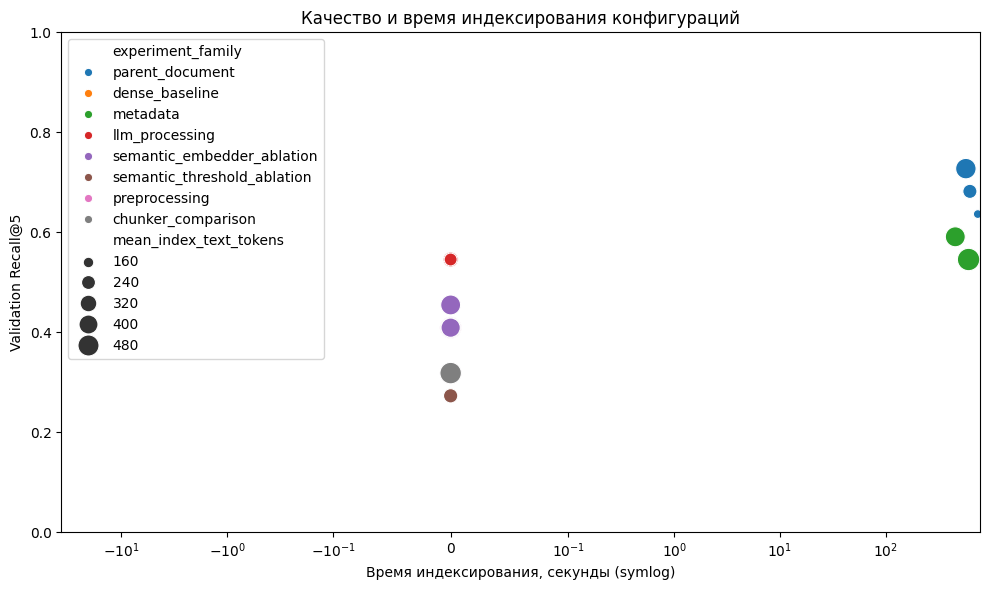

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=final_comparison_table,
    x="indexing_seconds", y="validation_Recall@5",
    hue="experiment_family", size="mean_index_text_tokens", sizes=(40, 260),
)
plt.xscale("symlog", linthresh=0.1)
plt.ylim(0, 1)
plt.title("Качество и время индексирования конфигураций")
plt.xlabel("Время индексирования, секунды (symlog)")
plt.ylabel("Validation Recall@5")
plt.tight_layout()
plt.savefig(OUT / "final_configuration_quality_vs_indexing_time.png", dpi=160, bbox_inches="tight")
plt.show()